# Лабораторна робота № 4. Реплікація MongoDB: відмовостійкість і лічильник

Дисципліна «Проєктування високонавантажених систем», викладач Родіонов А. М.

Виконав: Вовкотруб Олександр Віталійович, група ФБ-61мн.
КПІ ім. Ігоря Сікорського, ННФТІ, кафедра інформаційної безпеки.

Ноутбук є аналітичною частиною звіту. Усі числа, таблиці й рисунки звіту
обчислюються тут із виміряних даних `reports/data/task4-*.csv` і
`task4x-*.csv` (додаткове дослідження), протоколи
терміналу частини I беруться з `reports/logs/task4-part1-*.txt`, а розбір
відмов primary з `reports/logs/task4-failover-*.txt`. Наприкінці є жива
перевірка: справжній replica set і `mongo-bench` на зменшеному навантаженні.

## 0. Підготовка середовища

Корінь репозиторію шукаємо від поточної теки вгору до `Package.swift`, тому
ноутбук працює і зі своєї теки, і з кореня. Прапорець `RUN_LIVE` вмикає
розділ 10 зі справжнім replica set; вимкнути його можна змінною оточення
`HLS_NB_LIVE=0`.

In [1]:
import json
import os
import re
import shutil
import socket
import subprocess
import tempfile
import time
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "Package.swift").is_file():
            return path
    raise FileNotFoundError("Package.swift не знайдено вище від " + str(start))


ROOT = find_root(Path.cwd().resolve())
# Тека ноутбука: поточна, якщо ноутбук запущено з неї, інакше його
# місце в репозиторії.
LAB = Path.cwd() if (Path.cwd() / "solution.ipynb").is_file() else next(
    p for p in (ROOT / "lab4", ROOT / "Labs" / "04-mongodb") if p.is_dir())
DATA = ROOT / "reports" / "data"
LOGS = ROOT / "reports" / "logs"
ASSETS = LAB / "assets"
ASSETS.mkdir(exist_ok=True)

RUN_LIVE = os.environ.get("HLS_NB_LIVE", "1") != "0"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 100,
})
pd.set_option("display.width", 160)

# Ті самі кольори, що й у ноутбуках робіт № 1...3: один колір на прогін або
# сховище в усіх рисунках.
INK, GRID = "#1A233B", "#D7DAE3"
RUN_COLOR = {
    "w1": "#0E6BA8",
    "majority": "#1B8A5E",
    "w1-kill": "#0E6BA8",
    "majority-kill": "#1B8A5E",
    "majority-kill-noretry": "#B5432F",
}
RUNS = list(RUN_COLOR)
STORE_COLOR = {
    "In-memory": "#6B7280",
    "Hazelcast (CP)": "#1B8A5E",
    "MongoDB (majority)": "#7A4FB5",
    "PostgreSQL": "#0E6BA8",
    "Disk (fsync)": "#B5432F",
}
EXPECTED = 100_000


def uk(x: float, digits: int = 0) -> str:
    """Число в українському записі: 4 447,0 (нерозривний пробіл, кома)."""
    return f"{x:,.{digits}f}".replace(",", "\u00a0").replace(".", ",")


def save(fig, name: str) -> Path:
    """Зберегти рисунок у assets/ (dpi 200) і показати його в ноутбуці."""
    path = ASSETS / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path), width=820))
    print("збережено:", path.relative_to(ROOT))
    return path


def excerpt(rel: str, start: str, end: str | None = None, *, lines: int | None = None) -> None:
    """Надрукувати точний уривок файла з номерами рядків.

    Уривок починається з першого рядка, що містить `start`, і закінчується
    першим наступним рядком, що містить `end` (або через `lines` рядків).
    """
    text = (ROOT / rel).read_text(encoding="utf-8").splitlines()
    first = next(i for i, line in enumerate(text) if start in line)
    if end is not None:
        last = next(i for i in range(first + 1, len(text)) if end in text[i])
    else:
        last = first + (lines or 1) - 1
    print(f"{rel}, рядки {first + 1}...{last + 1}")
    for i in range(first, last + 1):
        print(f"{i + 1:4d} | {text[i]}")


print("корінь репозиторію:", ROOT.name)
print("RUN_LIVE =", RUN_LIVE)

корінь репозиторію: HighLoadSystems
RUN_LIVE = True


## 1. Постановка

Replica set `rs0` з трьох процесів `mongod` 8.2.12 на одній машині (P-S-S),
вузли `127.0.0.1:21430...21432`.

Частина I. Три сценарії в `mongosh`: запис з `w: 3` при вимкненому вузлі без
тайм-ауту і з `wtimeout`, перевибори primary після його зупинки.

Частина II. Один документ з лічильником `likes`; 10 окремих клієнтів
одночасно роблять по 10 000 `findOneAndUpdate({ $inc: { likes: 1 } })`,
тобто очікується 100 000. Прогони:

| Прогін | Write concern | Що відбувається |
|---|---|---|
| `w1` | `{ w: 1 }` | без відмов |
| `majority` | `{ w: "majority" }` | без відмов |
| `w1-kill` | `{ w: 1 }` | primary отримує SIGKILL на 35 % часу прогону |
| `majority-kill` | `{ w: "majority" }` | те саме |
| `majority-kill-noretry` | `{ w: "majority" }` | те саме, але повтори без `lsid` і `txnNumber` (контрольний прогін) |

Частина III. MongoDB з `w: "majority"` як сховище веб-лічильника з роботи
№ 1, 10 клієнтів по 10 000 запитів, порівняння з пам'яттю, диском,
PostgreSQL і Hazelcast.

Кожен прогін, крім контрольного, виконано тричі; у таблицях медіана,
мінімум і максимум.

## 2. Частина I: протоколи терміналу

`scripts/task4-part1.sh` виконує кожен сценарій і записує протокол: команди
оболонки з часом UTC і сесії `mongosh` з підказкою перед кожною введеною
командою. Зі цих самих файлів зроблено знімки терміналу у звіті
(рисунки 3.1...3.8). Нижче протоколи повністю, а потім час і стани вузлів,
які з них витягує код.

In [2]:
transcripts = {n: (LOGS / f"task4-part1-{n}.txt").read_text(encoding="utf-8") for n in (1, 2, 3)}
for n, text in transcripts.items():
    print(f"=============== reports/logs/task4-part1-{n}.txt ===============")
    print(text)

=============== reports/logs/task4-part1-1.txt ===============
# Сценарій 1. Один secondary вимкнено, запис з writeConcern { w: 3, wtimeout: 0 } (без тайм-ауту).
# Час у [квадратних дужках] і в ISODate(...) указано в UTC.
# mongosh читає команди зі stdin: текст після підказки rs0 [...]> і є введеною командою.

[17:45:51.038] $ scripts/mongo.sh status
rs0, term 1, seen from node1
node1  127.0.0.1:21430  PRIMARY                   health 1  optime 1793641547:16  (pid 553720)
node2  127.0.0.1:21431  SECONDARY                 health 1  optime 1793641547:16  lag 0 s  sync node1  (pid 553814)
node3  127.0.0.1:21432  SECONDARY                 health 1  optime 1793641547:16  lag 0 s  sync node1  (pid 553903)

[17:45:53.010] $ scripts/mongo.sh stop-node 3
node 3 stopped (SIGTERM, pid 553903), exited after 15.0 s
[17:46:08.196] $ scripts/mongo.sh wait-down 3
node1 sees node3 as (not reachable/healthy) after 0.5 s (Error connecting to 127.0.0.1:21432 :: caused by :: onInvoke :: caused by :: Connec

In [3]:
t1, t2, t3 = transcripts[1], transcripts[2], transcripts[3]


def after(text: str, command: str) -> str:
    """Рядок, який mongosh надрукував одразу після введеної команди."""
    lines = text.splitlines()
    i = next(i for i, line in enumerate(lines) if line.endswith("> " + command))
    return lines[i + 1].strip()


part1 = {}
# Сценарій 1: w: 3 без тайм-ауту чекає, доки повернеться вузол 3.
part1["1: час вставки з w: 3, с"] = float(after(t1, "(t1 - t0) / 1000"))
part1["1: вставка підтверджена"] = "acknowledged: true" in t1
start_node3 = re.search(r"\[(\d\d:\d\d:\d\d\.\d+)\] \$ scripts/mongo.sh start-node 3", t1)[1]
returned = re.search(r"let t1 = new Date\(\); t1\nISODate\('([^']+)'\)", t1)[1]
part1["1: від start-node 3 до відповіді, с"] = round(
    (pd.Timestamp(returned) - pd.Timestamp(f"{returned[:10]}T{start_node3}Z")).total_seconds(), 3)
part1["1: під час очікування документ читається з majority"] = \
    t1.count("note: 'w: 3, wtimeout: 0'") >= 3
# Сценарій 2: wtimeout 5000 мс.
part1["2: час до WriteConcernError, с"] = float(after(t2, "(new Date() - t0) / 1000"))
part1["2: код помилки"] = int(re.search(r"code: (\d+),\s*codeName: 'WriteConcernTimeout'", t2)[1])
part1["2: n у відповіді"] = int(re.search(r"Result: \{\s*n: (\d+)", t2)[1])
part1["2: документ знайдено разів (primary, node2, node3)"] = t2.count("note: 'w: 3, wtimeout: 5000'")
# Сценарій 3: перевибори.
part1["3: причина виборів"] = re.search(r"lastElectionReason: '(\w+)'", t3)[1]
part1["3: новий term"] = int(re.search(r"electionTerm: Long\('(\d+)'\)", t3)[1])
part1["3: новий primary"] = after(t3, "db.hello().primary")
part1["3: від stop-node 1 до виборів, с"] = float(after(
    t3, '(rs.status().electionCandidateMetrics.lastElectionDate - ISODate("2026-11-02T17:47:07.191Z")) / 1000'))
part1["3: majority-записи доступні після виборів, с"] = round(
    (pd.Timestamp(re.search(r"wMajorityWriteAvailabilityDate: ISODate\('([^']+)'\)", t3)[1])
     - pd.Timestamp(re.search(r"lastElectionDate: ISODate\('([^']+)'\)", t3)[1])).total_seconds(), 3)
part1["3: node1 після повернення бачить документів"] = t3.split("shell 1")[1].count("scenario: 3, n:")
caught = re.findall(r"(node\d) is SECONDARY and caught up with \w+ after ([\d.]+) s", "\n".join(transcripts.values()))
part1["наздоганяння після start-node, с"] = ", ".join(f"{node} {s}" for node, s in caught)
display(pd.Series(part1, name="значення").to_frame())

assert part1["1: вставка підтверджена"] and part1["1: час вставки з w: 3, с"] == 10.623
assert part1["2: код помилки"] == 64 and part1["2: n у відповіді"] == 1
assert part1["2: час до WriteConcernError, с"] == 5.049
assert part1["2: документ знайдено разів (primary, node2, node3)"] == 5  # 2 на primary, 2 на node2, 1 на node3
assert part1["3: новий primary"] == "127.0.0.1:21431" and part1["3: новий term"] == 2
assert part1["3: від stop-node 1 до виборів, с"] == 0.029
assert part1["3: node1 після повернення бачить документів"] == 3

,значення
"1: час вставки з w: 3, с",10.623
1: вставка підтверджена,True
"1: від start-node 3 до відповіді, с",1.571
1: під час очікування документ читається з majority,True
"2: час до WriteConcernError, с",5.049
2: код помилки,64
2: n у відповіді,1
"2: документ знайдено разів (primary, node2, node3)",5
3: причина виборів,stepUpRequestSkipDryRun
3: новий term,2


Сценарій 1: вставка з `w: 3` повернулася через 10,623 с, приблизно через
1,6 с після того, як вузол 3 запустили знову; поки вона чекала, документ
уже читався на primary і з `readConcern("majority")`. Сценарій 2:
`WriteConcernTimeout` (код 64) через 5,049 с, але `n: 1`, і документ є на
primary, на node2 (зокрема з `majority`) і, після повернення, на node3:
тайм-аут write concern запис не скасовує. Сценарій 3: після SIGTERM
primary передав роль node2 (`stepUpRequestSkipDryRun`, term 2) за 0,029 с;
старий primary повернувся як SECONDARY і має всі три документи, записані
без нього.

## 3. Клієнт: інкремент як retryable write

MongoKitten не реалізує retryable writes, тому клієнт сам будує команду
`findAndModify` з `lsid` сесії і новим `txnNumber` на кожен логічний запис.
Повтор надсилає ту саму команду з тим самим `txnNumber`, і сервер, який уже
виконав її, повертає збережений результат замість другого `$inc`:

In [4]:
excerpt("Sources/CounterCore/MongoCounterClient.swift", "private func retryableWrite(", "return try await retrying {")

Sources/CounterCore/MongoCounterClient.swift, рядки 211...230
 211 |     private func retryableWrite(
 212 |         documentID: String? = nil,
 213 |         update: Document,
 214 |         writeConcern: MongoWriteConcern? = nil
 215 |     ) async throws -> MongoOutcome<Int> {
 216 |         var command: Document = [
 217 |             "findAndModify": location.collection,
 218 |             "query": ["_id": documentID ?? location.documentID] as Document,
 219 |             "update": update,
 220 |             "new": true,
 221 |             "upsert": true,
 222 |             "writeConcern": (writeConcern ?? self.writeConcern).document,
 223 |         ]
 224 |         if retryableWrites {
 225 |             // A new logical write: the next transaction number. Every retry
 226 |             // of it sends this same number.
 227 |             command["lsid"] = ["id": sessionID] as Document
 228 |             command["txnNumber"] = lastTransactionNumber.add(1, ordering: .relaxed).newVal

Веб-сховище тримає пул з 10 таких клієнтів і позичає по одному на запит,
бо `txnNumber` однієї сесії мусить зростати, а не перемежовуватися:

In [5]:
excerpt("Sources/CounterCore/MongoCounterStore.swift", "public func increment() async", lines=3)

Sources/CounterCore/MongoCounterStore.swift, рядки 53...55
  53 |     public func increment() async throws {
  54 |         try await clients.withLease { _ = try await $0.increment() }
  55 |     }


## 4. Частина II: 10 клієнтів по 10 000 інкрементів

Сирі дані `reports/data/task4-bench.csv`, рядок на прогін. `acknowledged`:
інкременти, які сервер підтвердив; `lost_acknowledged`: різниця між ними
і фінальним значенням; `retries`: повторні надсилання після помилок;
`server_deduplicated`: приріст `serverStatus().transactions.retriedStatementsCount`,
тобто повтори, які сервер упізнав як уже виконані.

In [6]:
bench = pd.read_csv(DATA / "task4-bench.csv")
assert set(bench["run"]) == set(RUNS)
assert (bench["workers"] * bench["increments_per_worker"] == EXPECTED).all()
assert (bench["expected"] == EXPECTED).all() and (bench["acknowledged"] == EXPECTED).all()
assert (bench["errors"] == 0).all() and (bench["rollback_lines"] == 0).all()
bench[["repeat", "run", "seconds", "ops_per_sec", "final_value", "lost_acknowledged", "retries",
       "server_deduplicated", "killed_node", "kill_at_seconds", "failover_seconds", "elections"]]

,repeat,run,seconds,ops_per_sec,final_value,lost_acknowledged,retries,server_deduplicated,killed_node,kill_at_seconds,failover_seconds,elections
0,1,w1,21.9997,4545.5,100000,0,0,0,NaN,NaN,NaN,0
1,1,majority,101.5172,985.1,100000,0,0,0,NaN,NaN,NaN,0
2,2,w1,22.4869,4447.0,100000,0,0,0,NaN,NaN,NaN,0
3,2,majority,100.0766,999.2,100000,0,0,0,NaN,NaN,NaN,0
4,3,w1,29.1806,3426.9,100000,0,0,0,NaN,NaN,NaN,0
5,3,majority,103.4099,967.0,100000,0,0,0,NaN,NaN,NaN,0
6,1,w1-kill,34.4842,2899.9,99996,4,480,0,2.0,8.084,11.071,1
7,1,majority-kill,109.3340,914.6,100000,0,470,10,1.0,35.672,10.821,1
8,2,w1-kill,34.6597,2885.2,99999,1,490,2,2.0,8.088,11.315,1
9,2,majority-kill,112.3606,890.0,100000,0,480,7,1.0,35.672,11.095,1


Таблиця 4.1 звіту: час і пропускна здатність (медіана, мінімум, максимум).

In [7]:
g = bench.groupby("run", sort=False)
part2 = pd.DataFrame({
    "прогонів": g.size(),
    "медіана, с": g["seconds"].median(),
    "мін., с": g["seconds"].min(),
    "макс., с": g["seconds"].max(),
    "інкр./с (медіана)": g["ops_per_sec"].median(),
}).loc[RUNS]
display(part2.round(2))

PUBLISHED_41 = {  # прогін: (медіана, мін., макс., інкр./с), як у таблиці 4.1 звіту
    "w1": (22.49, 22.00, 29.18, 4447.0),
    "majority": (101.52, 100.08, 103.41, 985.1),
    "w1-kill": (34.66, 34.48, 35.73, 2885.2),
    "majority-kill": (112.36, 109.33, 139.85, 890.0),
    "majority-kill-noretry": (168.40, 168.40, 168.40, 593.8),
}
for run, values in PUBLISHED_41.items():
    row = part2.loc[run]
    got = (round(row["медіана, с"], 2), round(row["мін., с"], 2), round(row["макс., с"], 2),
           round(row["інкр./с (медіана)"], 1))
    assert got == values, (run, got, values)

,прогонів,"медіана, с","мін., с","макс., с",інкр./с (медіана)
run,,,,,
w1,3,22.49,22.00,29.18,4447.0
majority,3,101.52,100.08,103.41,985.1
w1-kill,3,34.66,34.48,35.73,2885.2
majority-kill,3,112.36,109.33,139.85,890.0
majority-kill-noretry,1,168.40,168.40,168.40,593.8


Таблиця 4.2 звіту: фінальне значення, втрачені підтверджені інкременти,
повтори і повтори, упізнані сервером, у кожному прогоні.

In [8]:
per_run = (bench.sort_values("repeat").groupby("run", sort=False)
           .agg(фінальне=("final_value", list), втрачено=("lost_acknowledged", list),
                повтори=("retries", list), упізнано_сервером=("server_deduplicated", list))
           .loc[RUNS])
display(per_run)

PUBLISHED_42 = {  # прогін: (фінальні значення, втрачено, повтори, упізнано сервером)
    "w1": ([100000] * 3, [0, 0, 0], [0, 0, 0], [0, 0, 0]),
    "majority": ([100000] * 3, [0, 0, 0], [0, 0, 0], [0, 0, 0]),
    "w1-kill": ([99996, 99999, 100000], [4, 1, 0], [480, 490, 450], [0, 2, 0]),
    "majority-kill": ([100000] * 3, [0, 0, 0], [470, 480, 426], [10, 7, 9]),
    "majority-kill-noretry": ([100010], [-10], [450], [0]),
}
for run, values in PUBLISHED_42.items():
    assert tuple(per_run.loc[run]) == values, (run, tuple(per_run.loc[run]), values)

,фінальне,втрачено,повтори,упізнано_сервером
run,,,,
w1,"[100000, 100000, 100000]","[0, 0, 0]","[0, 0, 0]","[0, 0, 0]"
majority,"[100000, 100000, 100000]","[0, 0, 0]","[0, 0, 0]","[0, 0, 0]"
w1-kill,"[99996, 99999, 100000]","[4, 1, 0]","[480, 490, 450]","[0, 2, 0]"
majority-kill,"[100000, 100000, 100000]","[0, 0, 0]","[470, 480, 426]","[10, 7, 9]"
majority-kill-noretry,[100010],[-10],[450],[0]


In [9]:
t = part2["медіана, с"]
r = part2["інкр./с (медіана)"]
print(f"majority / w1 за часом: {t['majority'] / t['w1']:.2f}")
print(f"додано відмовою: w1 {t['w1-kill'] - t['w1']:.2f} с, majority {t['majority-kill'] - t['majority']:.2f} с")
print(f"середня затримка інкремента (10 клієнтів / інкр./с): "
      f"w1 {1000 * 10 / r['w1']:.2f} мс, majority {1000 * 10 / r['majority']:.2f} мс")
kills = bench[bench["kill"]]
print(f"від kill до першого підтвердження: {kills['failover_seconds'].min():.2f}...{kills['failover_seconds'].max():.2f} с")
print(f"найдовший окремий інкремент у прогонах з kill: {kills['longest_op_seconds'].min():.2f}...{kills['longest_op_seconds'].max():.2f} с")
print(f"w1-kill: втрачено разом {int(bench.loc[bench['run'] == 'w1-kill', 'lost_acknowledged'].sum())} "
      f"підтверджених інкрементів з 300 000")
print("повторів на клієнта за секунду без primary:",
      ", ".join(f"{x:.1f}" for x in kills["retries"] / 10 / kills["failover_seconds"]))

exact = bench[bench["run"] != "w1-kill"].query("retryable_writes")
assert (exact["final_value"] == EXPECTED).all(), "усі прогони, крім w1-kill і контрольного, мають дати рівно 100 000"
assert (bench["elections"] == bench["kill"].astype(int)).all(), "одні вибори на кожен прогін з kill"

majority / w1 за часом: 4.51
додано відмовою: w1 12.17 с, majority 10.84 с
середня затримка інкремента (10 клієнтів / інкр./с): w1 2.25 мс, majority 10.15 мс
від kill до першого підтвердження: 10.30...11.31 с
найдовший окремий інкремент у прогонах з kill: 10.44...11.48 с
w1-kill: втрачено разом 5 підтверджених інкрементів з 300 000
повторів на клієнта за секунду без primary: 4.3, 4.3, 4.3, 4.3, 4.4, 3.9, 4.4


Рисунок 4.1 звіту: смуга це медіана, риска з засічками мінімум і максимум,
точки окремі повтори. У прогонах з kill частину часу займає пауза без
primary (від kill до першого підтвердження, медіана підписана).

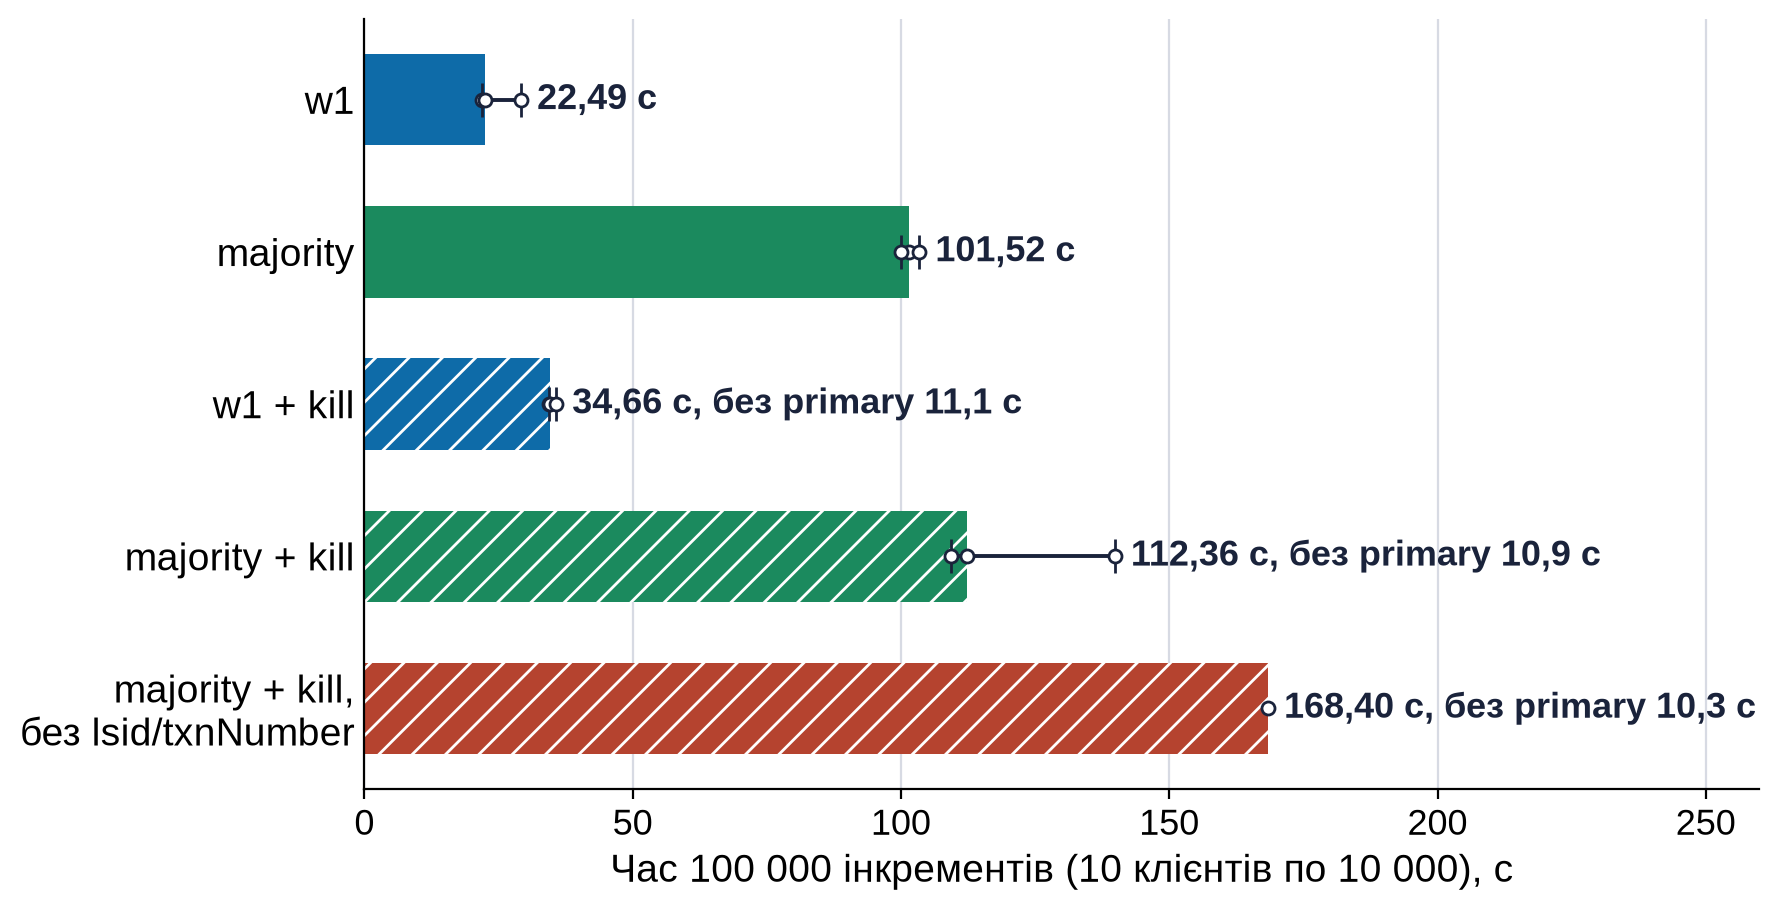

збережено: Labs/04-mongodb/assets/01-part2-time.png


In [10]:
LABEL = {
    "w1": "w1",
    "majority": "majority",
    "w1-kill": "w1 + kill",
    "majority-kill": "majority + kill",
    "majority-kill-noretry": "majority + kill,\nбез lsid/txnNumber",
}
fig, ax = plt.subplots(figsize=(9, 5.0))
order = RUNS[::-1]  # перший прогін зверху
for i, run in enumerate(order):
    row = part2.loc[run]
    runs = bench.loc[bench["run"] == run]
    kill = bool(runs["kill"].iloc[0])
    ax.barh(i, row["медіана, с"], height=0.6, color=RUN_COLOR[run], zorder=2,
            hatch="//" if kill else None, edgecolor="white" if kill else None, linewidth=0)
    if row["прогонів"] > 1:
        ax.errorbar(row["медіана, с"], i,
                    xerr=[[row["медіана, с"] - row["мін., с"]], [row["макс., с"] - row["медіана, с"]]],
                    fmt="none", ecolor=INK, elinewidth=1.4, capsize=6, zorder=3)
    ax.scatter(runs["seconds"], [i] * len(runs), s=22, color="white", edgecolor=INK, linewidth=1, zorder=4)
    label = f"{uk(row['медіана, с'], 2)} с"
    if kill:
        label += f", без primary {uk(runs['failover_seconds'].median(), 1)} с"
    ax.text(row["макс., с"] + 3, i, label, va="center", ha="left", color=INK, fontsize=13, fontweight="bold")
ax.set_yticks(range(len(order)), [LABEL[r] for r in order])
ax.set_xlim(0, 260)
ax.set_xlabel("Час 100 000 інкрементів (10 клієнтів по 10 000), с")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
save(fig, "01-part2-time.png");

Рисунок 4.2 звіту: відхилення фінального значення від 100 000 у кожному
повторі. Нуль означає точний лічильник; мінус це втрачені підтверджені
інкременти, плюс це інкременти, пораховані двічі.

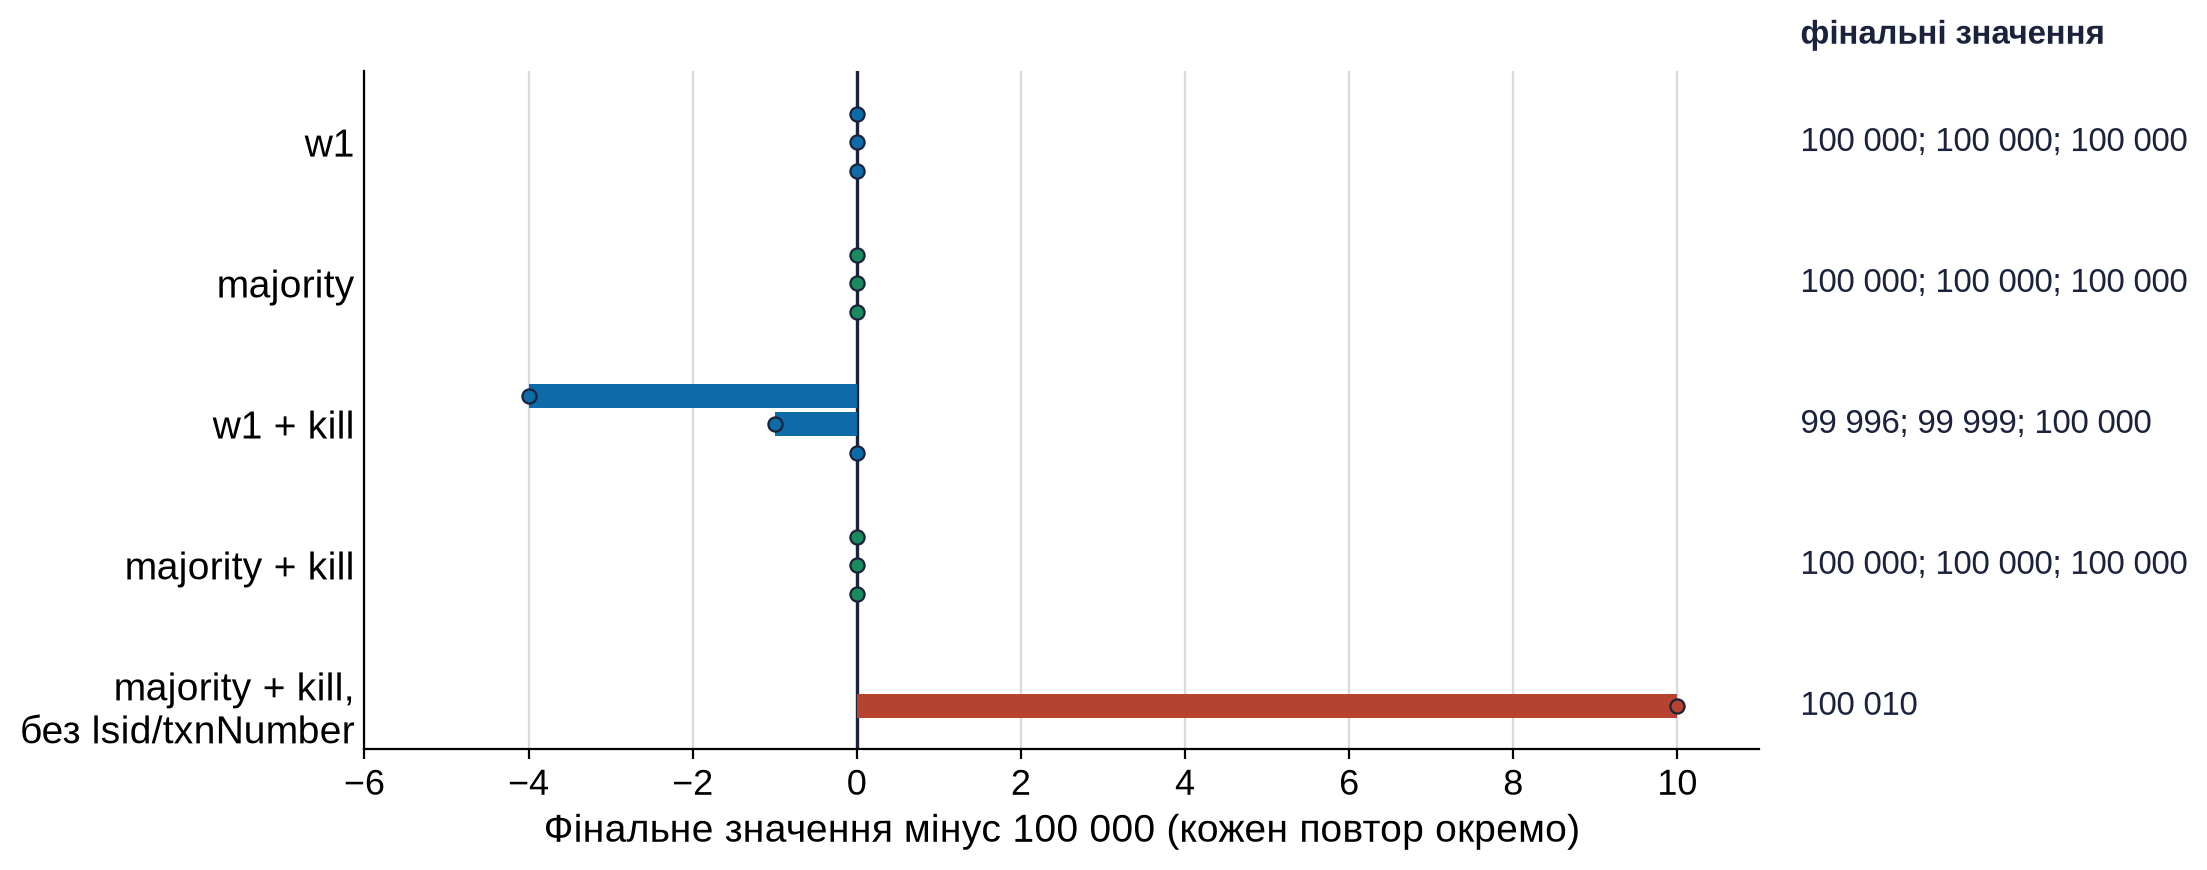

збережено: Labs/04-mongodb/assets/02-part2-final-value.png


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, run in enumerate(order):
    runs = bench.loc[bench["run"] == run].sort_values("repeat")
    dev = runs["final_value"] - EXPECTED
    offsets = [0.0] if len(runs) == 1 else [0.2, 0.0, -0.2][:len(runs)]  # повтор 1 зверху
    ax.barh([i + o for o in offsets], dev, height=0.17, color=RUN_COLOR[run], zorder=2)
    ax.scatter(dev, [i + o for o in offsets], s=26, color=RUN_COLOR[run], edgecolor=INK, linewidth=0.8, zorder=3)
    text = "; ".join(uk(v) for v in runs["final_value"])
    ax.text(11.5, i, text, va="center", ha="left", color=INK, fontsize=12)
ax.axvline(0, color=INK, linewidth=1.2, zorder=1)
ax.set_yticks(range(len(order)), [LABEL[r] for r in order])
ax.set_xlim(-6, 11)
ax.set_xticks(range(-6, 11, 2))
ax.set_xlabel("Фінальне значення мінус 100 000 (кожен повтор окремо)")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.text(11.5, len(order) - 0.35, "фінальні значення", ha="left", va="bottom", color=INK, fontsize=12,
        fontweight="bold")
save(fig, "02-part2-final-value.png");

Без відмов обидва write concern дають рівно 100 000, а `majority` у 4,5
раза повільніший: середня затримка інкремента 10,2 мс проти 2,2 мс, бо
`majority` чекає запису в журнал на більшості вузлів. Після SIGKILL
primary кожен прогін простоює 10,3...11,3 с, доки решта вузлів не обере
новий primary (`electionTimeoutMillis` 10 000 мс). `w1-kill` втратив 4, 1
і 0 підтверджених інкрементів. `majority-kill` у всіх трьох повторах дав
рівно 100 000, а контрольний прогін без `lsid` і `txnNumber` дав 100 010:
10 інкрементів, що були в дорозі під час відмови, пораховано двічі.

## 5. Відмова primary за логами mongod

Для кожного прогону з kill `scripts/task4.sh` зберіг вивід `mongo-bench` і
рядки журналів усіх трьох вузлів за час прогону
(`reports/logs/task4-failover-<прогін>-<повтор>.txt`). Звідти беремо, хто
став primary і в якому term, і дві позиції oplog: `targetOpTime`, до якої
новий primary наздогнав дані після виборів, і `oplogTruncateAfterPoint`,
до якої вбитий вузол обрізав свій oplog під час відновлення після
аварійного вимкнення, тобто що з його записів реально встигло на диск.

In [12]:
def optime(value: str) -> tuple[int, int]:
    seconds, increment = value.split(":")
    return int(seconds), int(increment)


failovers = []
for path in sorted(LOGS.glob("task4-failover-*.txt")):
    text = path.read_text(encoding="utf-8")
    m = re.match(r"task4-failover-(.+)-(\d+)\.txt", path.name)
    elected = re.search(r"^\S+\s+(node\d)\s+ELECTION Election succeeded, assuming primary role\s+\{\"term\":(\d+)\}",
                        text, re.M)
    target = optime(re.search(r'"targetOpTime":\{"ts":"([\d:]+)"', text)[1])
    truncated = optime(re.search(r'"oplogTruncateAfterPoint":\{"":"([\d:]+)"\}', text)[1])
    assert target[0] == truncated[0], "обидві позиції в одній секунді, тож різниця це кількість записів oplog"
    failovers.append({
        "прогін": m[1], "повтор": int(m[2]),
        "новий primary": elected[1], "term": int(elected[2]),
        "записів oplog, яких не було на диску вбитого вузла": target[1] - truncated[1],
        "rollback": "ROLLBACK" in text and "Файлів rollback немає" not in text,
    })
failovers = pd.DataFrame(failovers)
failovers = failovers.merge(
    bench[["run", "repeat", "killed_node", "kill_at_seconds", "failover_seconds", "lost_acknowledged",
           "server_deduplicated"]],
    left_on=["прогін", "повтор"], right_on=["run", "repeat"]).drop(columns=["run", "repeat"])
failovers["прогін"] = pd.Categorical(failovers["прогін"], RUNS, ordered=True)
failovers = failovers.sort_values(["прогін", "повтор"]).reset_index(drop=True)
display(failovers)

gap = failovers.groupby("прогін", observed=True)["записів oplog, яких не було на диску вбитого вузла"].agg(list)
print(gap)
assert gap["w1-kill"] == [452, 2386, 346] and gap["majority-kill"] == [2, 8, 0]
assert not failovers["rollback"].any()

PUBLISHED_43 = [  # (прогін, повтор, kill с, вбито, новий primary, term, розрив, втрачено), таблиця 4.3 звіту
    ("w1-kill", 1, 8.08, "node2", "node1", 16, 452, 4),
    ("w1-kill", 2, 8.09, "node2", "node1", 18, 2386, 1),
    ("w1-kill", 3, 8.09, "node2", "node3", 20, 346, 0),
    ("majority-kill", 1, 35.67, "node1", "node2", 17, 2, 0),
    ("majority-kill", 2, 35.67, "node1", "node2", 19, 8, 0),
    ("majority-kill", 3, 36.01, "node3", "node2", 21, 0, 0),
]
got = [(row["прогін"], row["повтор"], round(row["kill_at_seconds"], 2), f"node{int(row['killed_node'])}",
        row["новий primary"], row["term"], row["записів oplog, яких не було на диску вбитого вузла"],
        row["lost_acknowledged"]) for _, row in failovers.iterrows() if row["прогін"] != "majority-kill-noretry"]
assert got == PUBLISHED_43, got

,прогін,повтор,новий primary,term,"записів oplog, яких не було на диску вбитого вузла",rollback,killed_node,kill_at_seconds,failover_seconds,lost_acknowledged,server_deduplicated
0,w1-kill,1,node1,16,452,False,2.0,8.084,11.071,4,0
1,w1-kill,2,node1,18,2386,False,2.0,8.088,11.315,1,2
2,w1-kill,3,node3,20,346,False,2.0,8.086,10.302,0,0
3,majority-kill,1,node2,17,2,False,1.0,35.672,10.821,0,10
4,majority-kill,2,node2,19,8,False,1.0,35.672,11.095,0,7
5,majority-kill,3,node2,21,0,False,3.0,36.007,10.879,0,9
6,majority-kill-noretry,1,node1,22,0,False,2.0,35.665,10.301,-10,0


прогін
w1-kill                  [452, 2386, 346]
majority-kill                   [2, 8, 0]
majority-kill-noretry                 [0]
Name: записів oplog, яких не було на диску вбитого вузла, dtype: object


Таблиця 4.3 звіту. У прогонах `w1-kill` вбитий primary після перезапуску
мав на диску на 346...2386 записів oplog менше, ніж новий primary: з
`w: 1` журнал скидається на диск періодично (раз на 100 мс), а secondary
журналюють кожну застосовану пачку. Записи, які primary підтвердив, але не
встиг ні віддати secondary, ні записати в журнал, зникли разом з його
пам'яттю, тому rollback не було. У прогонах `majority-kill` розрив
0...8 записів, бо кожен запис з `majority` примусово синхронізує журнал.

In [13]:
print("уривок журналів, w1-kill, повтор 1:")
lines = (LOGS / "task4-failover-w1-kill-1.txt").read_text(encoding="utf-8").splitlines()
for line in lines:
    if re.search(r"ELECTION (Starting|Election succeeded)|Caught up to the latest|Removing unapplied|"
                 r"Recovering from stable|SERVER RESTARTED|Member is now in state DOWN", line):
        print(line[:150])

уривок журналів, w1-kill, повтор 1:
18:35:05.541  node3  REPL     Member is now in state DOWN  {"hostAndPort":"127.0.0.1:21431","heartbeatMessage":"Error connecting to 127.0.0.1:21431 ::
18:35:05.542  node1  REPL     Member is now in state DOWN  {"hostAndPort":"127.0.0.1:21431","heartbeatMessage":"Error connecting to 127.0.0.1:21431 ::
18:35:16.556  node1  ELECTION Starting an election, since we've seen no PRIMARY in election timeout period  {"electionTimeoutPeriodMillis":10000}
18:35:16.561  node1  ELECTION Election succeeded, assuming primary role  {"term":16}
18:35:16.562  node1  REPL     Caught up to the latest optime known via heartbeats after becoming primary  {"targetOpTime":{"ts":"1793644505:11766","t"
18:35:32.102  node2  CONTROL  ***** SERVER RESTARTED *****
18:35:32.863  node2  REPL     Removing unapplied oplog entries after oplogTruncateAfterPoint  {"oplogTruncateAfterPoint":{"":"1793644505:11314"}}
18:35:32.865  node2  REPL     Recovering from stable timestamp  {"stableTim

## 6. Частина III: веб-лічильник на MongoDB

`counter-server --store mongo`: `findAndModify` з `$inc` і
`w: "majority"`, читання `/count` з `readConcern: "majority"`. Дані для
порівняння: пам'ять і диск з `task1.csv` (лише рядки з 10 клієнтами),
PostgreSQL з `task2-web.csv`, Hazelcast з `task3-web.csv`, MongoDB з
`task4-web.csv`. Скрізь 10 клієнтів по 10 000 запитів.

In [14]:
t1csv = pd.read_csv(DATA / "task1.csv")
web = pd.concat([
    t1csv[t1csv["clients"] == 10],
    pd.read_csv(DATA / "task2-web.csv"),
    pd.read_csv(DATA / "task3-web.csv"),
    pd.read_csv(DATA / "task4-web.csv"),
], ignore_index=True)
web["сховище"] = web["store"].map({"memory": "In-memory", "disk": "Disk (fsync)", "postgres": "PostgreSQL",
                                   "hazelcast": "Hazelcast (CP)", "mongo": "MongoDB (majority)"})
assert (web["total_requests"] == EXPECTED).all() and web["correct"].all()
display(web[["сховище", "repeat", "seconds", "rps", "final_value", "correct"]])

STORES = ["In-memory", "Disk (fsync)", "PostgreSQL", "Hazelcast (CP)", "MongoDB (majority)"]
w = web.groupby("сховище")
part3 = pd.DataFrame({
    "медіана, с": w["seconds"].median(),
    "мін., с": w["seconds"].min(),
    "макс., с": w["seconds"].max(),
    "запитів/с (медіана)": w["rps"].median(),
    "мін. запитів/с": w["rps"].min(),
    "макс. запитів/с": w["rps"].max(),
}).loc[STORES]
display(part3.round(2))

PUBLISHED_44 = {  # сховище: (медіана, мін., макс., запитів/с), як у таблиці 4.4 звіту
    "In-memory": (3.20, 2.92, 3.31, 31256.0),
    "Disk (fsync)": (818.08, 814.26, 824.12, 122.2),
    "PostgreSQL": (302.44, 199.76, 306.17, 330.6),
    "Hazelcast (CP)": (8.88, 8.79, 9.08, 11259.7),
    "MongoDB (majority)": (133.59, 121.80, 156.01, 748.6),
}
for store, values in PUBLISHED_44.items():
    row = part3.loc[store]
    got = (round(row["медіана, с"], 2), round(row["мін., с"], 2), round(row["макс., с"], 2),
           round(row["запитів/с (медіана)"], 1))
    assert got == values, (store, got, values)

,сховище,repeat,seconds,rps,final_value,correct
0,In-memory,1,2.9155,34299.7,100000,True
1,In-memory,2,3.3096,30215.1,100000,True
2,In-memory,3,3.1994,31256.0,100000,True
3,Disk (fsync),1,818.0793,122.2,100000,True
4,Disk (fsync),2,814.2633,122.8,100000,True
5,Disk (fsync),3,824.1182,121.3,100000,True
6,PostgreSQL,1,199.7578,500.6,100000,True
7,PostgreSQL,2,302.4360,330.6,100000,True
8,PostgreSQL,3,306.1745,326.6,100000,True
9,Hazelcast (CP),1,8.7884,11378.6,100000,True


,"медіана, с","мін., с","макс., с",запитів/с (медіана),мін. запитів/с,макс. запитів/с
сховище,,,,,,
In-memory,3.20,2.92,3.31,31256.0,30215.1,34299.7
Disk (fsync),818.08,814.26,824.12,122.2,121.3,122.8
PostgreSQL,302.44,199.76,306.17,330.6,326.6,500.6
Hazelcast (CP),8.88,8.79,9.08,11259.7,11007.6,11378.6
MongoDB (majority),133.59,121.80,156.01,748.6,641.0,821.1


In [15]:
rps = part3["запитів/с (медіана)"]
mongo = rps["MongoDB (majority)"]
print(f"In-memory / MongoDB: {rps['In-memory'] / mongo:.1f}")
print(f"Hazelcast / MongoDB: {rps['Hazelcast (CP)'] / mongo:.1f}")
print(f"MongoDB / PostgreSQL: {mongo / rps['PostgreSQL']:.2f}")
print(f"MongoDB / Disk: {mongo / rps['Disk (fsync)']:.2f}")
print(f"веб-лічильник / mongo-bench majority: {mongo / r['majority']:.2f}")
spread = part3.loc["MongoDB (majority)"]
print(f"розкид часу MongoDB: {spread['мін., с']:.2f}...{spread['макс., с']:.2f} с, "
      f"{100 * (spread['макс., с'] - spread['мін., с']) / spread['медіана, с']:.1f} % від медіани")

In-memory / MongoDB: 41.8
Hazelcast / MongoDB: 15.0
MongoDB / PostgreSQL: 2.26
MongoDB / Disk: 6.13
веб-лічильник / mongo-bench majority: 0.76
розкид часу MongoDB: 121.80...156.01 с, 25.6 % від медіани


Рисунок 4.3 звіту: логарифмічна шкала, бо сховища відрізняються на два з
половиною порядки. Смуга це медіана, риска мінімум і максимум.

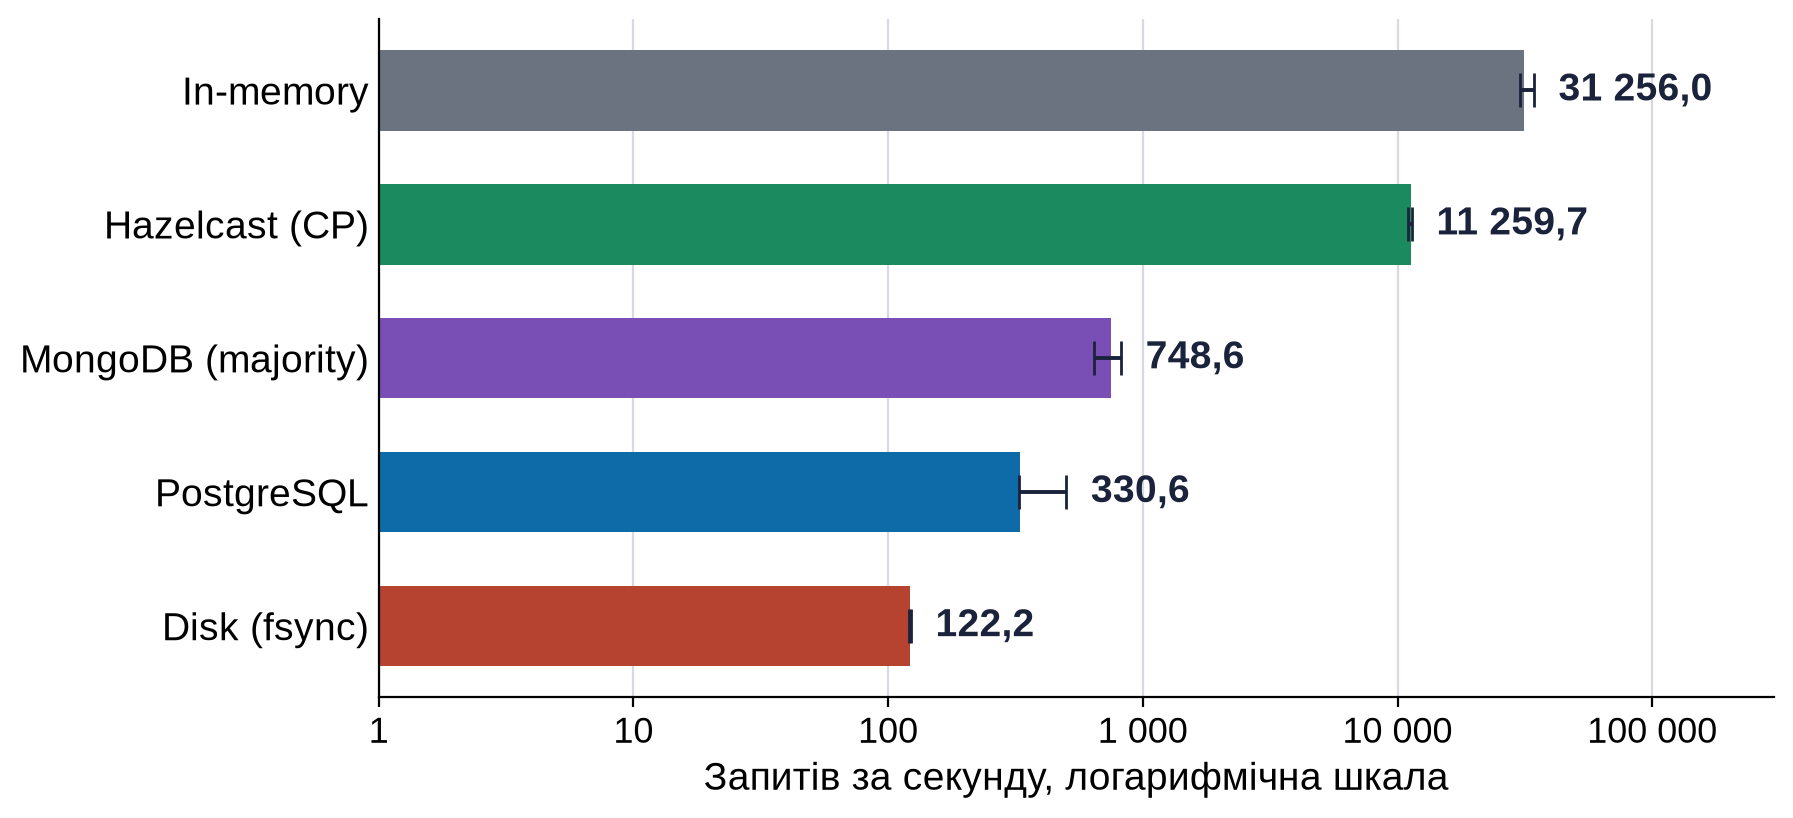

збережено: Labs/04-mongodb/assets/03-part3-stores-rps.png


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.4))
order3 = part3.sort_values("запитів/с (медіана)").index.tolist()  # найшвидше зверху
for i, s in enumerate(order3):
    row = part3.loc[s]
    med = row["запитів/с (медіана)"]
    ax.barh(i, med, height=0.6, color=STORE_COLOR[s], zorder=2)
    ax.errorbar(med, i, xerr=[[med - row["мін. запитів/с"]], [row["макс. запитів/с"] - med]],
                fmt="none", ecolor=INK, elinewidth=1.4, capsize=6, zorder=3)
    ax.text(row["макс. запитів/с"] * 1.25, i, uk(med, 1), va="center", ha="left",
            color=INK, fontsize=14, fontweight="bold")
ax.set_yticks(range(len(order3)), order3)
ax.set_xscale("log")
ax.set_xlim(1, 3e5)
ax.set_xticks([1, 10, 100, 1_000, 10_000, 100_000],
              ["1", "10", "100", uk(1_000), uk(10_000), uk(100_000)])
ax.minorticks_off()
ax.set_xlabel("Запитів за секунду, логарифмічна шкала")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
save(fig, "03-part3-stores-rps.png");

MongoDB з `w: "majority"` дав 748,6 запитів/с: у 2,3 раза більше за
PostgreSQL і в 6,1 раза більше за файл з `fsync`, але в 15 разів менше за
Hazelcast і в 41,8 раза менше за пам'ять. Як і PostgreSQL та файл, він
чекає на диск при кожному інкременті, але очікування write concern
відбувається вже після застосування `$inc`, тож 10 клієнтів чекають
журнал паралельно, а не по черзі. Веб-варіант повільніший за прямий
`mongo-bench majority` (985,1 інкр./с) через HTTP між клієнтом і сервером.

## 7. Додаткове дослідження: відкат і аномалії читання

Розділи 7...9 відповідають розділу «Додаткове дослідження» звіту. Виміри
зроблено 10.11.2026 на тій самій машині, але з mongod 8.3.13 і mongosh
2.14.0. Тут вони перераховуються з нових файлів `reports/data/task4x-*.csv`
і `reports/logs/task4x-*.txt`, а кожне число таблиць 5.N звіту перевіряється
`assert`.

`scripts/task4x-rollback.sh` піднімає окремий replica set з
`enableTestCommands`, вимикає реплікацію на обох secondary (failpoint
`stopReplProducer`), робить на primary 5 інкрементів і 5 вставок з
`{ w: 1, j: true }`, заморожує primary (SIGSTOP; у варіанті kill це SIGKILL),
дає обрати новий primary і повертає старий. Протокол
`task4x-rollback.txt` і знімки з нього є рисунками 5.1...5.8 звіту.

In [17]:
import gzip
import math

import numpy as np

rb_text = (LOGS / "task4x-rollback.txt").read_text(encoding="utf-8")
rbk_text = (LOGS / "task4x-rollback-kill.txt").read_text(encoding="utf-8")


def log_time(text: str, needle: str) -> pd.Timestamp:
    """Час першого рядка протоколу rollback_log, що містить `needle`."""
    line = next(l for l in text.splitlines() if needle in l and re.match(r"\d\d:\d\d:\d\d\.\d{3} ", l))
    return pd.Timestamp("2026-11-10T" + line[:12])


def block_after(text: str, command: str) -> list[str]:
    """Рядки виводу команди оболонки до першого порожнього рядка."""
    lines = text.splitlines()
    i = next(i for i, l in enumerate(lines) if "$ " + command in l)
    out = []
    for l in lines[i + 1:]:
        if not l.strip():
            break
        out.append(l)
    return out


rollback = {}
for name, text in (("pause", rb_text), ("kill", rbk_text)):
    reverted = json.loads(re.search(r"Operations reverted by rollback\s+(\{.*\})", text)[1])
    summary = re.search(r"Rollback summary\s+(\{.*\})", text, re.S)[1].replace("\n", "")
    start, end = log_time(text, "Transition to ROLLBACK"), log_time(text, "ROLLBACK Transition to SECONDARY")
    docs = [json.loads(l) for l in block_after(text, "bsondump --quiet")]
    oplog = [json.loads(l) for l in block_after(text, "oplog_dump")]
    rollback[name] = {
        "новий primary знайдено через, с": float(re.search(r"term 2, found after ([\d.]+) s", text)[1]),
        "відкочено insert": reverted["insert"], "відкочено update": reverted["update"],
        "записів oplog у rollback": int(re.search(r'"totalEntriesRolledBackIncludingNoops":(\d+)', summary)[1]),
        "тривалість ROLLBACK, с": round((end - start).total_seconds(), 3),
        "документів у rollback-файлі": len(docs),
        "likes у rollback-файлі": next(d["likes"]["$numberInt"] for d in docs if d["_id"] == "counter"),
        "oplog: u / i / n": "/".join(str(sum(e["op"] == op for e in oplog)) for op in "uin"),
    }
rollback = pd.DataFrame(rollback)
display(rollback)

hold = (log_time(rb_text, "Transition to ROLLBACK") - log_time(rb_text, "Starting rollback")).total_seconds()
window = (log_time(rb_text, "Starting rollback") - log_time(rb_text, "Stepping down from primary")).total_seconds()
print(f"pause: від Stepping down до Starting rollback {window:.3f} с, затримка failpoint {hold:.3f} с")
assert rollback.loc["відкочено insert"].tolist() == [5, 5] and rollback.loc["відкочено update"].tolist() == [5, 5]
assert rollback.loc["записів oplog у rollback"].tolist() == [12, 12]
assert rollback.loc["документів у rollback-файлі"].tolist() == [6, 6]
assert rollback.loc["likes у rollback-файлі"].tolist() == ["105", "105"]
assert rollback.loc["oplog: u / i / n"].tolist() == ["5/5/2", "5/5/2"]
assert rollback.loc["новий primary знайдено через, с"].tolist() == [11.4, 10.6]
assert rollback.loc["тривалість ROLLBACK, с"].tolist() == [0.309, 0.712] and round(hold, 3) == 5.0 and round(window, 3) == 0.002
# Після rollback: likes 110, документів lost-* немає.
after_rb = rb_text.split("Після rollback")[1]
assert "likes: 110" in after_rb and re.search(r"countDocuments\(\{ _id: /\^lost-/ \}\)\n0\n", after_rb)

,pause,kill
"новий primary знайдено через, с",11.4,10.6
відкочено insert,5,5
відкочено update,5,5
записів oplog у rollback,12,12
"тривалість ROLLBACK, с",0.309,0.712
документів у rollback-файлі,6,6
likes у rollback-файлі,105,105
oplog: u / i / n,5/5/2,5/5/2


pause: від Stepping down до Starting rollback 0.002 с, затримка failpoint 5.000 с


Варіант kill: після SIGKILL і `start-node` вузол відновив з журналу весь
свій oplog. `oplogTruncateAfterPoint` при перезапуску збігається з
`lastOptimeRolledBack` у підсумку rollback, тобто нічого з підтвердженого з
`j: true` не обрізано, усе відкочено вже через rollback.

In [18]:
node1 = [json.loads(l) for l in (LOGS / "task4x-rollback-kill-mongo-node1.txt").read_text(encoding="utf-8").splitlines()
         if l.startswith("{")]
truncate_points = [e["attr"]["oplogTruncateAfterPoint"][""]["$timestamp"] for e in node1
                   if e["msg"] == "Removing unapplied oplog entries after oplogTruncateAfterPoint"]
last_rolled = json.loads(re.search(r'"lastOptimeRolledBack":(\{.*?\}),"commonPoint"',
                                   re.search(r"Rollback summary\s+(\{.*\})", rbk_text, re.S)[1].replace("\n", ""))[1])
print("oplogTruncateAfterPoint при перезапуску:", truncate_points[0])
print("lastOptimeRolledBack:", last_rolled["ts"]["$timestamp"])
assert truncate_points[0] == last_rolled["ts"]["$timestamp"] == {"t": 1794311948, "i": 1}

oplogTruncateAfterPoint при перезапуску: {'t': 1794311948, 'i': 1}
lastOptimeRolledBack: {'t': 1794311948, 'i': 1}


Таблиці 5.2 і 5.3 звіту: кожне читання протоколу скрипт повторив окремим
запитом і записав у `task4x-reads.csv`.

In [19]:
reads = pd.read_csv(DATA / "task4x-reads.csv")
display(reads)


def read_row(scenario, step, node, concern):
    row = reads[(reads.scenario == scenario) & (reads.step == step) & (reads.node == node)
                & (reads.read_concern == concern)].iloc[0]
    return row["error"] if isinstance(row["error"], str) else (int(row["likes"]), int(row["lost_docs"]))


PUBLISHED_52 = [  # (крок, вузол, read concern, likes і lost-* або помилка), таблиця 5.2 звіту
    ("w1 written before failure", "node1", "local", (105, 5)),
    ("w1 written before failure", "node1", "majority", (100, 0)),
    ("w1 written before failure", "node1", "linearizable", "MaxTimeMSExpired"),
    ("w1 written before failure", "node2", "local", (100, 0)),
    ("new primary elected", "node3", "local", (110, 0)),
    ("old primary is SECONDARY with rollback held", "node1", "local", (105, 5)),
    ("old primary is SECONDARY with rollback held", "node1", "majority", (100, 0)),
    ("after rollback", "node1", "local", (110, 0)),
    ("after rollback", "node3", "majority", (110, 0)),
]
for step, node, concern, value in PUBLISHED_52:
    assert read_row("rollback", step, node, concern) == value, (step, node, concern)
PUBLISHED_53 = [  # таблиця 5.3 звіту: застаріле читання з відсталого secondary
    ("node lags after majority inc", "node3", "linearizable", (111, 0)),
    ("node lags after majority inc", "node3", "local", (111, 0)),
    ("node lags after majority inc", "node2", "local", (110, 0)),
    ("node lags after majority inc", "node2", "majority", (110, 0)),
    ("node lags after majority inc", "node2", "linearizable", "NotWritablePrimary"),
    ("caught up", "node2", "local", (111, 0)),
]
for step, node, concern, value in PUBLISHED_53:
    assert read_row("stale", step, node, concern) == value, (step, node, concern)
rolled = reads[reads.rolled_back_later == "yes"]
assert set(rolled.read_concern) == {"local"}, "відкочене бачило лише читання local"

,scenario,step,node,node_state,read_concern,likes,lost_docs,error,rolled_back_later
0,rollback,w1 written before failure,node1,PRIMARY,local,105.0,5.0,NaN,yes
1,rollback,w1 written before failure,node1,PRIMARY,majority,100.0,0.0,NaN,no
2,rollback,w1 written before failure,node1,PRIMARY,linearizable,NaN,NaN,MaxTimeMSExpired,NaN
3,rollback,w1 written before failure,node2,SECONDARY,local,100.0,0.0,NaN,no
4,rollback,new primary elected,node3,PRIMARY,local,110.0,0.0,NaN,no
5,rollback,old primary is SECONDARY with rollback held,node1,SECONDARY,local,105.0,5.0,NaN,yes
6,rollback,old primary is SECONDARY with rollback held,node1,SECONDARY,majority,100.0,0.0,NaN,no
7,rollback,after rollback,node1,SECONDARY,local,110.0,0.0,NaN,no
8,rollback,after rollback,node3,PRIMARY,majority,110.0,0.0,NaN,no
9,stale,node lags after majority inc,node3,PRIMARY,linearizable,111.0,0.0,NaN,no


### Розподіл затримок

`mongo-bench --latency-out` записав для кожного підтвердженого інкременту
момент завершення від початку прогону, затримку (разом з повторами) і
кількість повторів (`task4x-latency-raw-*.csv.gz`, по 100 000 рядків).
Перцентилі рахуємо за найближчим рангом і звіряємо з
`task4x-latency.csv` і таблицею 5.4 звіту.

In [20]:
LAT_RUNS = ["w1", "majority", "majority-kill"]
lat_raw = {run: pd.read_csv(DATA / f"task4x-latency-raw-{run}.csv.gz") for run in LAT_RUNS}
lat_bench = pd.read_csv(DATA / "task4x-latency-bench.csv").set_index("run")
lat_file = pd.read_csv(DATA / "task4x-latency.csv").set_index("run")
PCTS = [("p50", 50), ("p90", 90), ("p99", 99), ("p99,9", 99.9)]


def nearest_rank(values: np.ndarray, p: float) -> float:
    return float(values[max(1, math.ceil(p / 100 * len(values))) - 1])


lat = {}
for run, df in lat_raw.items():
    v = np.sort(df["latency_ms"].to_numpy())
    row = {"час, с": lat_bench.loc[run, "seconds"], "інкр./с": lat_bench.loc[run, "ops_per_sec"],
           "фінальне": int(lat_bench.loc[run, "final_value"]), "середня, мс": round(v.mean(), 3)}
    row |= {name: round(nearest_rank(v, p), 3) for name, p in PCTS}
    row["max, мс"] = round(float(v[-1]), 3)
    lat[run] = row
lat = pd.DataFrame(lat).T
display(lat)

for run in LAT_RUNS:
    f = lat_file.loc[run]
    got = [lat.loc[run, c] for c in ("середня, мс", "p50", "p90", "p99", "p99,9", "max, мс")]
    assert got == [f[c] for c in ("mean_ms", "p50_ms", "p90_ms", "p99_ms", "p99_9_ms", "max_ms")], run
PUBLISHED_54 = {  # прогін: (час, інкр./с, середня, p50, p90, p99, p99,9, max), таблиця 5.4 звіту
    "w1": (12.74, 7852.1, 1.241, 0.413, 1.701, 20.104, 59.299, 141.5),
    "majority": (97.49, 1025.8, 9.728, 9.679, 13.618, 16.944, 25.789, 49.447),
    "majority-kill": (107.67, 928.8, 10.754, 9.826, 13.226, 17.106, 26.486, 10411.932),
}
for run, values in PUBLISHED_54.items():
    r_ = lat.loc[run]
    got = (round(r_["час, с"], 2), r_["інкр./с"], r_["середня, мс"], r_["p50"], r_["p90"], r_["p99"],
           r_["p99,9"], r_["max, мс"])
    assert got == values, (run, got)
assert (lat["фінальне"] == EXPECTED).all()

w1_slow = int((lat_raw["w1"]["latency_ms"] > 10).sum())
kill_df = lat_raw["majority-kill"]
slow = kill_df[kill_df["latency_ms"] > 1000]
print(f"w1: довших за 10 мс {w1_slow} ({100 * w1_slow / EXPECTED:.1f} %), p99 / p50 = "
      f"{lat.loc['w1', 'p99'] / lat.loc['w1', 'p50']:.0f}")
print(f"majority-kill: довших за 1 с {len(slow)}, від {slow.latency_ms.min() / 1000:.3f} до "
      f"{slow.latency_ms.max() / 1000:.3f} с, усі з повторами: {bool((slow.retries > 0).all())}")
assert w1_slow == 1839 and len(slow) == 10 and (slow.retries > 0).all()
assert round(slow.latency_ms.min() / 1000, 3) == 10.397 and round(slow.latency_ms.max() / 1000, 3) == 10.412

,"час, с",інкр./с,фінальне,"середня, мс",p50,p90,p99,"p99,9","max, мс"
w1,12.7354,7852.1,100000.0,1.241,0.413,1.701,20.104,59.299,141.500
majority,97.4887,1025.8,100000.0,9.728,9.679,13.618,16.944,25.789,49.447
majority-kill,107.6700,928.8,100000.0,10.754,9.826,13.226,17.106,26.486,10411.932


w1: довших за 10 мс 1839 (1.8 %), p99 / p50 = 49
majority-kill: довших за 1 с 10, від 10.397 до 10.412 с, усі з повторами: True


Пауза на часовій шкалі `majority-kill`: найдовший проміжок між двома
сусідніми підтвердженнями і порожні інтервали по 100 мс
(`task4x-timeline-majority-kill.csv`). Для порівняння `mongo-bench` сам
виміряв час від kill до першого підтвердження (`failover_seconds`), а
журнали вузлів дають момент, коли вузли побачили primary недоступним, і
момент, коли новий primary дозволив запис.

In [21]:
done = np.sort(kill_df["completed_seconds"].to_numpy())
gaps = np.diff(done)
i = int(gaps.argmax())
timeline = pd.read_csv(DATA / "task4x-timeline-majority-kill.csv")
empty = timeline[timeline.acknowledged == 0]
kill_log = (LOGS / "task4x-latency-majority-kill.txt").read_text(encoding="utf-8")
down_at = pd.Timestamp("2026-11-10T" + re.search(r"^(\S+)\s+node\d\s+REPL\s+Member is now in state DOWN", kill_log, re.M)[1])
writable_at = pd.Timestamp("2026-11-10T" + re.search(r"^(\S+)\s+node\d\s+REPL\s+Transition to primary complete", kill_log, re.M)[1])
retry_kinds = dict((k, int(n)) for n, k in re.findall(r"retried (\d+)x after (\S+)", kill_log))
kb = lat_bench.loc["majority-kill"]
print(f"останнє підтвердження перед паузою {done[i]:.3f} с, наступне через {gaps[i]:.3f} с")
print(f"порожніх інтервалів по 100 мс: {len(empty)}, від {empty.bucket_start_s.min()} до {empty.bucket_start_s.max()} с")
print(f"mongo-bench: kill на {kb.kill_at_seconds} с, до першого підтвердження {kb.failover_seconds} с, повторів {kb.retries}")
print(f"журнали: DOWN {down_at.time()}, запис дозволено {writable_at.time()}, різниця {(writable_at - down_at).total_seconds():.2f} с")
print("повтори за причинами:", retry_kinds)
assert round(done[i], 3) == 34.13 and round(gaps[i], 3) == 10.397
assert len(empty) == 103 and empty.bucket_start_s.min() == 34.2 and empty.bucket_start_s.max() == 44.4
assert np.allclose(np.diff(empty.bucket_start_s), 0.1), "порожні інтервали йдуть поспіль"
assert (kb.kill_at_seconds, kb.failover_seconds, kb.retries) == (34.242, 10.285, 450)
assert round((writable_at - down_at).total_seconds(), 2) == 10.21
assert retry_kinds == {"MongoError.cannotConnect.noAvailableHosts": 440, "MongoError.queryFailure.connectionClosed": 10}
assert "ROLLBACK" not in kill_log

останнє підтвердження перед паузою 34.130 с, наступне через 10.397 с
порожніх інтервалів по 100 мс: 103, від 34.2 до 44.4 с
mongo-bench: kill на 34.242 с, до першого підтвердження 10.285 с, повторів 450
журнали: DOWN 11:54:53.175000, запис дозволено 11:55:03.381000, різниця 10.21 с
повтори за причинами: {'MongoError.cannotConnect.noAvailableHosts': 440, 'MongoError.queryFailure.connectionClosed': 10}


Рисунок 5.9 звіту: перцентилі затримки, логарифмічна шкала. Рисунок 5.10:
підтверджені інкременти за секунду в прогоні `majority-kill` (інтервали по
100 мс, помножені на 10, і ковзне середнє за 1 с).

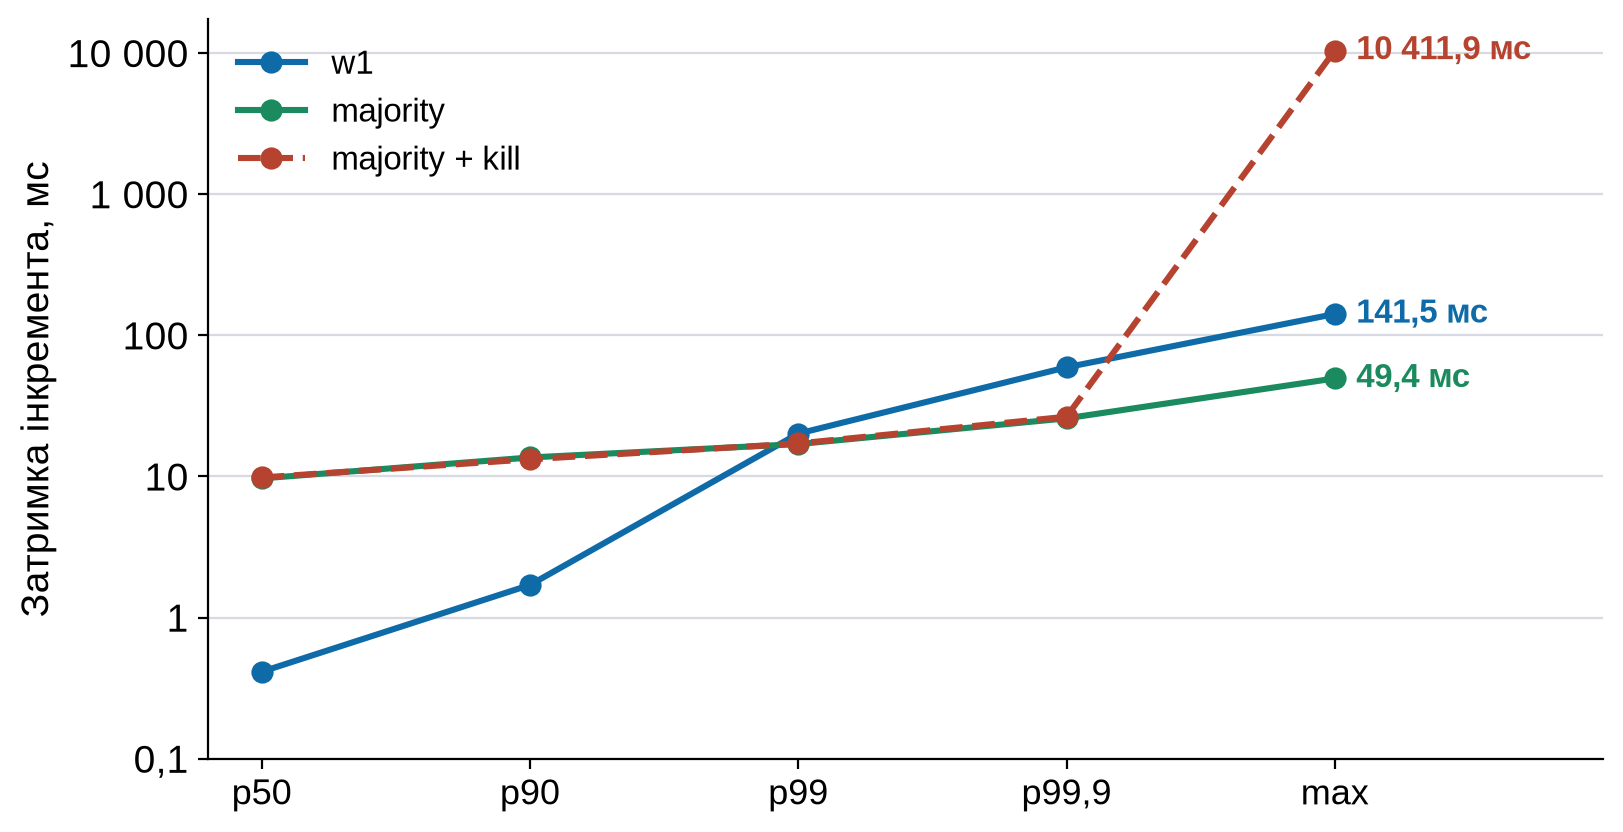

збережено: Labs/04-mongodb/assets/04-extra-latency.png


In [22]:
LAT_COLOR = {"w1": RUN_COLOR["w1"], "majority": RUN_COLOR["majority"], "majority-kill": "#B5432F"}
LAT_LABEL = {"w1": "w1", "majority": "majority", "majority-kill": "majority + kill"}
cols = ["p50", "p90", "p99", "p99,9", "max, мс"]
fig, ax = plt.subplots(figsize=(9, 4.8))
for run in LAT_RUNS:
    ys = [lat.loc[run, c] for c in cols]
    ax.plot(range(len(cols)), ys, marker="o", lw=2.2, ms=7, color=LAT_COLOR[run], label=LAT_LABEL[run],
            ls="--" if run == "majority-kill" else "-")
    ax.text(len(cols) - 1 + 0.08, ys[-1], uk(ys[-1], 1) + " мс", va="center", ha="left", color=LAT_COLOR[run],
            fontsize=12, fontweight="bold")
ax.set_yscale("log")
ax.set_xticks(range(len(cols)), ["p50", "p90", "p99", "p99,9", "max"])
ax.set_yticks([0.1, 1, 10, 100, 1000, 10000], ["0,1", "1", "10", "100", uk(1000), uk(10000)])
ax.minorticks_off()
ax.set_xlim(-0.2, len(cols) - 1 + 1.0)
ax.set_ylabel("Затримка інкремента, мс")
ax.yaxis.grid(True, color=GRID, zorder=0)
ax.legend(loc="upper left", frameon=False)
save(fig, "04-extra-latency.png");

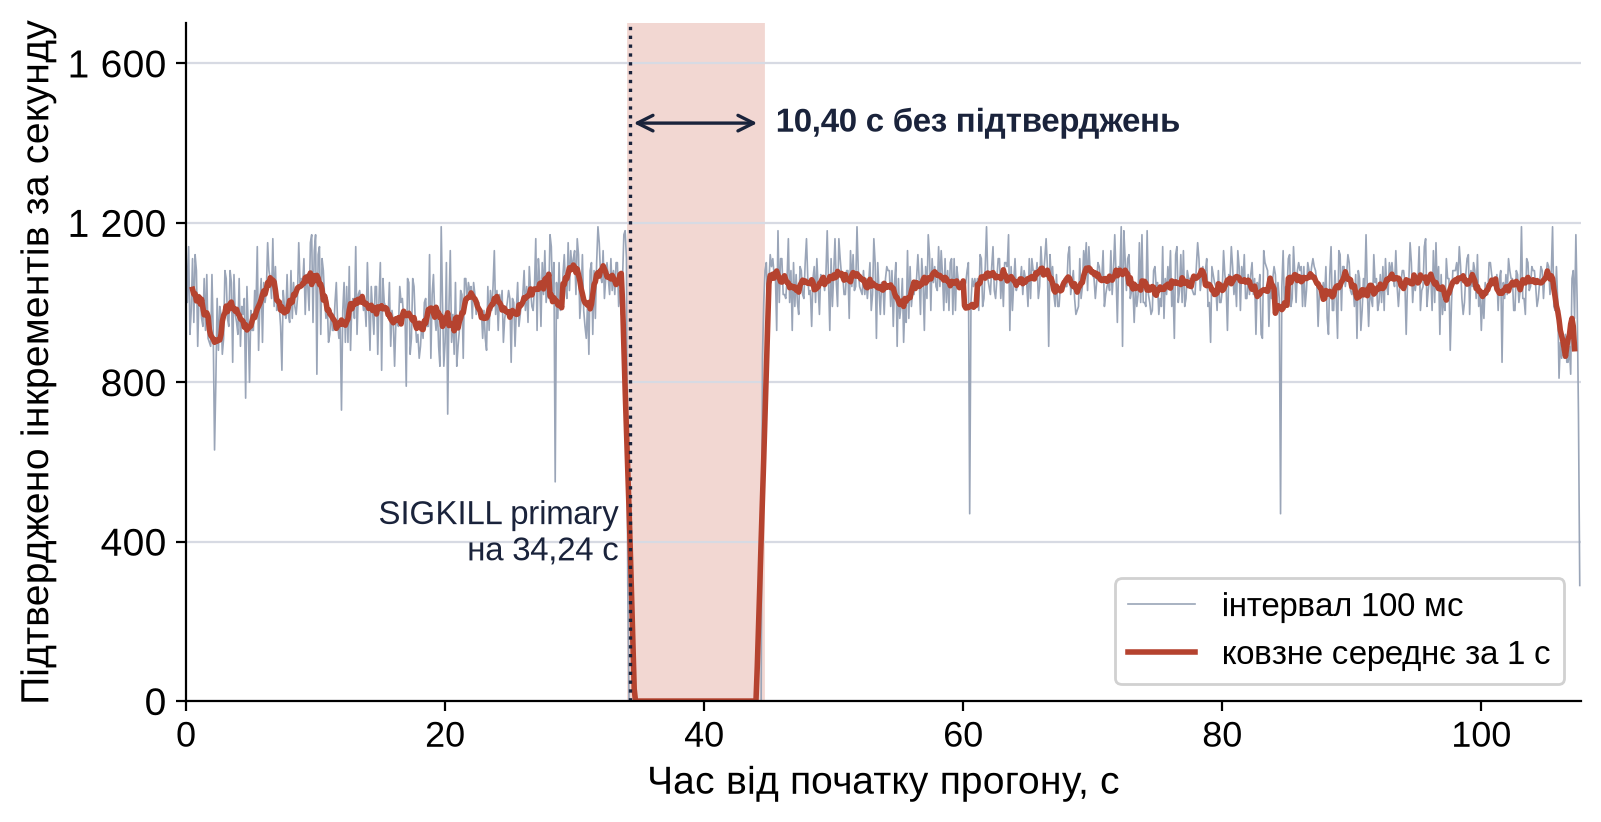

збережено: Labs/04-mongodb/assets/05-extra-timeline.png


In [23]:
fig, ax = plt.subplots(figsize=(9, 4.4))
tl = timeline.copy()
tl["ops"] = tl.acknowledged * 10
ax.plot(tl.bucket_start_s, tl.ops, color="#9AA5B8", lw=0.6, label="інтервал 100 мс")
ax.plot(tl.bucket_start_s, tl.ops.rolling(10, center=True).mean(), color=LAT_COLOR["majority-kill"], lw=2,
        label="ковзне середнє за 1 с")
ax.axvspan(done[i], done[i] + gaps[i], color="#F2D7D2", zorder=0)
ax.axvline(kb.kill_at_seconds, color=INK, lw=1.2, ls=":")
ax.text(kb.kill_at_seconds - 0.8, 420, f"SIGKILL primary\nна {uk(kb.kill_at_seconds, 2)} с", ha="right", va="center",
        color=INK, fontsize=12)
ax.annotate("", xy=(done[i] + gaps[i], 1450), xytext=(done[i], 1450),
            arrowprops={"arrowstyle": "<->", "color": INK, "lw": 1.2})
ax.text(done[i] + gaps[i] + 1.0, 1450, f"{uk(gaps[i], 2)} с без підтверджень", ha="left", va="center",
        color=INK, fontsize=12, fontweight="bold")
ax.set_xlim(0, tl.bucket_start_s.max() + 0.1)
ax.set_ylim(0, 1700)
ax.set_yticks(range(0, 1601, 400), [uk(v) for v in range(0, 1601, 400)])
ax.set_xlabel("Час від початку прогону, с")
ax.set_ylabel("Підтверджено інкрементів за секунду")
ax.yaxis.grid(True, color=GRID, zorder=0)
ax.legend(loc="lower right", frameon=True, framealpha=0.9)
save(fig, "05-extra-timeline.png");

## 8. Додаткове дослідження: пропускна здатність

`scripts/task4x-throughput.py` проганяє варіанти почергово (A, B, A, B, ...)
по 3 рази: розвідувальні серії на 10 × 2 000, підсумкова серія `final` на
10 × 10 000. До і після кожного прогону він знімає `serverStatus` і час CPU
кожного вузла (`task4x-throughput-metrics.csv`). Медіани метрик рахуються
окремо по primary і по secondary.

In [24]:
tp = pd.read_csv(DATA / "task4x-throughput.csv")
tpm = pd.read_csv(DATA / "task4x-throughput-metrics.csv")
assert len(tp) == 93 and tp["correct"].all() and (tp["final_value"] == tp["expected"]).all()
assert (tpm["flow_control_us"] == 0).all() and (tpm["flow_control_lagged"] == 0).all(), "flow control не вмикався"


def tp_summary(experiment: str) -> pd.DataFrame:
    runs = tp[tp.experiment == experiment]
    m = tpm[tpm.experiment == experiment]
    p, s = m[m.state == "PRIMARY"].groupby("label"), m[m.state == "SECONDARY"].groupby("label")
    g = runs.groupby("label", sort=False)["ops_per_s"]
    return pd.DataFrame({
        "прогонів": g.size(), "інкр./с": g.median(), "мін.": g.min(), "макс.": g.max(),
        "P синхр./інкр.": p["log_syncs_per_op"].median(), "P синхр., мс": p["log_sync_ms_mean"].median(),
        "P конфл./інкр.": p["write_conflicts_per_op"].median(), "P wtime, мс": p["wtime_ms_mean"].median(),
        "P CPU, %": p["cpu_percent"].median(),
        "S синхр./інкр.": s["log_syncs_per_op"].median(), "S синхр., мс": s["log_sync_ms_mean"].median(),
        "S oplog/пачку": s["apply_ops_per_batch"].median(),
    }).loc[g.size().index]


series = {e: tp_summary(e) for e in tp.experiment.unique()}
for e, df in series.items():
    print(f"== {e}: 10 × {tp[tp.experiment == e].increments_per_client.iloc[0]}")
    display(df.round(3))

== hotdoc: 10 × 2000


,прогонів,інкр./с,мін.,макс.,P синхр./інкр.,"P синхр., мс",P конфл./інкр.,"P wtime, мс","P CPU, %",S синхр./інкр.,"S синхр., мс",S oplog/пачку
label,,,,,,,,,,,,
w1,3,4676.6,4524.5,4875.4,0.002,8.599,3.888,7.500,294.2,0.020,10.244,11.720
w1-shards10,3,6873.3,6819.2,7435.5,0.002,6.682,0.000,3.909,238.0,0.014,9.638,25.905
majority,3,882.3,880.4,948.4,0.157,7.040,3.574,9.348,97.3,0.220,4.958,2.925
majority-shards10,3,1043.4,1014.9,1050.3,0.140,6.683,0.000,8.185,78.7,0.204,4.450,5.360


== journal-interval: 10 × 2000


,прогонів,інкр./с,мін.,макс.,P синхр./інкр.,"P синхр., мс",P конфл./інкр.,"P wtime, мс","P CPU, %",S синхр./інкр.,"S синхр., мс",S oplog/пачку
label,,,,,,,,,,,,
majority-interval100,3,886.8,874.8,888.2,0.156,7.029,3.643,9.323,99.4,0.22,4.996,2.885
majority-interval1,3,881.1,880.8,886.7,0.157,7.051,3.591,9.385,98.7,0.22,4.998,2.895
majority-interval500,3,882.7,871.8,891.8,0.156,7.047,3.704,9.329,99.3,0.22,4.972,2.870


== unsafe-journal: 10 × 2000


,прогонів,інкр./с,мін.,макс.,P синхр./інкр.,"P синхр., мс",P конфл./інкр.,"P wtime, мс","P CPU, %",S синхр./інкр.,"S синхр., мс",S oplog/пачку
label,,,,,,,,,,,,
majority,3,884.3,882.7,884.8,0.157,7.023,3.666,9.348,98.9,0.221,4.954,2.875
majority-nojournal-UNSAFE,3,3367.1,3340.3,3432.6,0.003,8.769,3.270,0.639,248.2,0.030,9.933,7.865


... (4 outputs left out)

== client: 10 × 2000


,прогонів,інкр./с,мін.,макс.,P синхр./інкр.,"P синхр., мс",P конфл./інкр.,"P wtime, мс","P CPU, %",S синхр./інкр.,"S синхр., мс",S oplog/пачку
label,,,,,,,,,,,,
bench-majority,3,986.2,970.8,998.9,0.173,5.671,3.519,8.225,106.7,0.214,4.597,2.91
web-async-ahc,3,867.6,843.5,879.5,0.174,6.400,3.481,9.030,99.0,0.228,4.916,2.86
web-async-nio,3,892.4,870.7,895.5,0.169,6.460,3.430,8.949,99.9,0.224,4.838,2.92
web-handler-nio,3,886.1,879.9,904.2,0.167,6.561,3.559,9.065,99.9,0.224,4.876,2.90
web-raw-nio,3,895.4,892.9,899.9,0.166,6.546,3.646,9.053,99.6,0.220,4.892,2.85
web-async-ahc-clients20,3,860.2,843.2,886.9,0.173,6.458,3.568,9.032,99.1,0.227,4.899,2.87


== final: 10 × 10000


,прогонів,інкр./с,мін.,макс.,P синхр./інкр.,"P синхр., мс",P конфл./інкр.,"P wtime, мс","P CPU, %",S синхр./інкр.,"S синхр., мс",S oplog/пачку
label,,,,,,,,,,,,
majority,3,997.6,984.0,1008.7,0.170,5.763,3.945,8.235,99.7,0.212,4.637,2.725
w1,3,4641.1,4448.7,5466.0,0.002,8.785,3.986,7.500,294.5,0.022,9.814,11.475
web,3,870.7,856.9,894.9,0.159,6.953,4.112,9.197,92.8,0.224,4.937,2.690
majority-zero-fill,3,1520.0,1419.5,1535.7,0.184,3.410,3.284,5.172,146.6,0.208,3.066,2.690
w1-zero-fill,3,5228.1,4658.4,5959.5,0.002,2.904,4.026,3.000,346.7,0.082,2.120,10.590
web-zero-fill,3,1474.6,1300.7,1525.4,0.190,3.371,3.253,4.803,144.0,0.217,3.090,2.650
majority-zero-fill-shards10,3,1634.1,1592.5,1690.7,0.172,3.364,0.000,5.034,105.9,0.184,3.128,5.255
w1-zero-fill-shards10,3,7812.8,6602.0,9125.4,0.001,3.018,0.000,2.364,272.2,0.050,2.045,29.085
web-zero-fill-shards10,3,1596.0,1396.2,1647.8,0.179,3.331,0.000,4.672,107.6,0.190,3.147,5.260


Таблиця 5.5 звіту: до і після на повних 10 × 10 000. «Звіт» береться з
таблиць 4.1 і 4.4 (розділи 4 і 6 ноутбука), «до» і «після» з серії `final`.

In [25]:
final = series["final"]
before_after = pd.DataFrame({
    "звіт": [r["majority"], rps["MongoDB (majority)"], r["w1"]],
    "до": final.loc[["majority", "web", "w1"], "інкр./с"].values,
    "до мін.": final.loc[["majority", "web", "w1"], "мін."].values,
    "до макс.": final.loc[["majority", "web", "w1"], "макс."].values,
    "після": final.loc[["majority-zero-fill", "web-zero-fill", "w1-zero-fill"], "інкр./с"].values,
    "після мін.": final.loc[["majority-zero-fill", "web-zero-fill", "w1-zero-fill"], "мін."].values,
    "після макс.": final.loc[["majority-zero-fill", "web-zero-fill", "w1-zero-fill"], "макс."].values,
    "10 документів": final.loc[["majority-zero-fill-shards10", "web-zero-fill-shards10",
                                "w1-zero-fill-shards10"], "інкр./с"].values,
}, index=["mongo-bench majority", "веб-лічильник majority", "mongo-bench w1"])
before_after["зміна, %"] = (100 * (before_after["після"] / before_after["до"] - 1)).round(1)
before_after["10 док. / 1 док., %"] = (100 * (before_after["10 документів"] / before_after["після"] - 1)).round(1)
display(before_after.round(1))

PUBLISHED_55 = {  # режим: (звіт, до, після, мін. після, макс. після, зміна %), таблиця 5.5 звіту
    "mongo-bench majority": (985.1, 997.6, 1520.0, 1419.5, 1535.7, 52.4),
    "веб-лічильник majority": (748.6, 870.7, 1474.6, 1300.7, 1525.4, 69.4),
    "mongo-bench w1": (4447.0, 4641.1, 5228.1, 4658.4, 5959.5, 12.6),
}
for mode, values in PUBLISHED_55.items():
    row = before_after.loc[mode]
    got = tuple(round(row[c], 1) for c in ("звіт", "до", "після", "після мін.", "після макс.", "зміна, %"))
    assert got == values, (mode, got)
assert before_after.loc["mongo-bench w1", ["до мін.", "до макс."]].round(1).tolist() == [4448.7, 5466.0]
PUBLISHED_59 = {"mongo-bench majority": (1634.1, 7.5), "веб-лічильник majority": (1596.0, 8.2),
                "mongo-bench w1": (7812.8, 49.4)}  # таблиця 5.9 звіту
for mode, (value, change) in PUBLISHED_59.items():
    assert (round(before_after.loc[mode, "10 документів"], 1), before_after.loc[mode, "10 док. / 1 док., %"]) == \
        (value, change), mode

,звіт,до,до мін.,до макс.,після,після мін.,після макс.,10 документів,"зміна, %","10 док. / 1 док., %"
mongo-bench majority,985.1,997.6,984.0,1008.7,1520.0,1419.5,1535.7,1634.1,52.4,7.5
веб-лічильник majority,748.6,870.7,856.9,894.9,1474.6,1300.7,1525.4,1596.0,69.4,8.2
mongo-bench w1,4447.0,4641.1,4448.7,5466.0,5228.1,4658.4,5959.5,7812.8,12.6,49.4


Таблиця 5.6 звіту: куди йде час інкремента з `majority` до і після
`zero_fill`. Зайнятість журналу: синхронізацій на інкремент × інкр./с ×
середній час однієї синхронізації.

In [26]:
cols56 = ["інкр./с", "P wtime, мс", "P синхр./інкр.", "P синхр., мс", "S синхр./інкр.", "S синхр., мс", "P CPU, %"]
bottleneck = final.loc[["majority", "majority-zero-fill"], cols56].T
bottleneck.loc["затримка 10 / інкр./с, мс"] = 10_000 / final.loc[["majority", "majority-zero-fill"], "інкр./с"].values
for node in ("P", "S"):
    bottleneck.loc[f"{node} зайнятість журналу, с/с"] = (final.loc[["majority", "majority-zero-fill"], f"{node} синхр./інкр."]
        * final.loc[["majority", "majority-zero-fill"], "інкр./с"]
        * final.loc[["majority", "majority-zero-fill"], f"{node} синхр., мс"] / 1000).values
    bottleneck.loc[f"{node} інкрементів на синхронізацію"] = \
        1 / final.loc[["majority", "majority-zero-fill"], f"{node} синхр./інкр."].values
display(bottleneck.round(3))
b = bottleneck
assert b.loc["затримка 10 / інкр./с, мс"].round(2).tolist() == [10.02, 6.58]
assert b.loc["P wtime, мс"].round(3).tolist() == [8.235, 5.172]
assert round(b.loc["P wtime, мс", "majority"] / b.loc["затримка 10 / інкр./с, мс", "majority"] * 100) == 82
assert b.loc["P синхр./інкр."].round(3).tolist() == [0.170, 0.184] and b.loc["S синхр./інкр."].round(3).tolist() == [0.212, 0.208]
assert b.loc["P синхр., мс"].round(3).tolist() == [5.763, 3.410] and b.loc["S синхр., мс"].round(3).tolist() == [4.637, 3.066]
assert b.loc["P зайнятість журналу, с/с"].round(2).tolist() == [0.98, 0.95]
assert b.loc["S зайнятість журналу, с/с"].round(2).tolist() == [0.98, 0.97]
assert b.loc["P інкрементів на синхронізацію"].round(1).tolist()[0] == 5.9
assert b.loc["S інкрементів на синхронізацію"].round(1).tolist()[0] == 4.7
assert b.loc["P CPU, %"].round(0).tolist() == [100, 147]

unsafe = series["unsafe-journal"]
print(f"без журналу на більшості (НЕБЕЗПЕЧНО): {unsafe.loc['majority-nojournal-UNSAFE', 'інкр./с']} проти "
      f"{unsafe.loc['majority', 'інкр./с']} інкр./с, ×{unsafe.loc['majority-nojournal-UNSAFE', 'інкр./с'] / unsafe.loc['majority', 'інкр./с']:.1f}; "
      f"wtime {unsafe.loc['majority', 'P wtime, мс']:.2f} -> {unsafe.loc['majority-nojournal-UNSAFE', 'P wtime, мс']:.2f} мс")
assert (unsafe.loc["majority-nojournal-UNSAFE", "інкр./с"], unsafe.loc["majority", "інкр./с"]) == (3367.1, 884.3)
assert round(unsafe.loc["majority-nojournal-UNSAFE", "P wtime, мс"], 2) == 0.64

label,majority,majority-zero-fill
інкр./с,997.600,1520.000
"P wtime, мс",8.235,5.172
P синхр./інкр.,0.170,0.184
"P синхр., мс",5.763,3.410
S синхр./інкр.,0.212,0.208
"S синхр., мс",4.637,3.066
"P CPU, %",99.700,146.600
"затримка 10 / інкр./с, мс",10.024,6.579
"P зайнятість журналу, с/с",0.977,0.954
P інкрементів на синхронізацію,5.882,5.435


без журналу на більшості (НЕБЕЗПЕЧНО): 3367.1 проти 884.3 інкр./с, ×3.8; wtime 9.35 -> 0.64 мс


Таблиця 5.7 звіту: проба `fdatasync` без MongoDB
(`scripts/task4x-journal-probe.py`): дописування по 2 048 байтів з
`fdatasync` після кожного у файл, підготовлений трьома способами.

In [27]:
probe = pd.read_csv(DATA / "task4x-journal-probe.csv")
probe_t = probe.pivot(index="file", columns="processes", values="mean_ms").loc[["fallocate", "sparse", "zero-filled"]]
display(probe_t)
assert probe_t[1].tolist() == [3.435, 3.446, 1.468] and probe_t[3].tolist() == [4.051, 3.989, 2.650]

single = (pd.read_csv(DATA / "task4x-throughput-probe.csv").groupby(["profile", "write_concern"])["mean_ms"]
          .median().unstack(0).loc[["w1", "w1-j", "majority"]])
display(single)
assert single["default"].tolist() == [1.150, 3.917, 4.232] and single["zero-fill"].tolist() == [1.112, 3.442, 3.660]

processes,1,3
file,,
fallocate,3.435,4.051
sparse,3.446,3.989
zero-filled,1.468,2.650


profile,default,zero-fill
write_concern,,
w1,1.150,1.112
w1-j,3.917,3.442
majority,4.232,3.660


Таблиця 5.8 звіту: гарячий документ. Пропускна здатність і конфлікти запису
з серії `hotdoc`, CPU з окремого профілю `perf` (`task4x-throughput-perf.csv`):
«розгортання винятків» означає семпли в `libgcc_s`, тобто обробку
`WriteConflictException`.

In [28]:
perf = pd.read_csv(DATA / "task4x-throughput-perf.csv")
unwind = perf[perf.part == "C++ exception unwinding"].set_index("label")
hot = series["hotdoc"][["інкр./с", "мін.", "макс.", "P конфл./інкр."]].join(
    unwind[["user_cpu_us_per_op", "percent_of_user_samples"]])
display(hot)
PUBLISHED_58 = {  # варіант: (інкр./с, конфліктів на інкремент, мкс CPU на інкремент, % розгортання)
    "w1": (4676.6, 3.89, 538, 14.1), "w1-shards10": (6873.3, 0.0, 301, 0.0),
    "majority": (882.3, 3.57, 881, 7.6), "majority-shards10": (1043.4, 0.0, 586, 0.0),
}
for label, values in PUBLISHED_58.items():
    row = hot.loc[label]
    got = (row["інкр./с"], round(row["P конфл./інкр."], 2), row["user_cpu_us_per_op"],
           round(row["percent_of_user_samples"], 1))
    assert got == values, (label, got)
print(f"конфліктів на інкремент на primary з одним документом, медіани серій: "
      f"{series['final'].loc[['majority', 'w1'], 'P конфл./інкр.'].round(2).tolist()}")

,інкр./с,мін.,макс.,P конфл./інкр.,user_cpu_us_per_op,percent_of_user_samples
label,,,,,,
w1,4676.6,4524.5,4875.4,3.888,538,14.14
w1-shards10,6873.3,6819.2,7435.5,0.000,301,0.01
majority,882.3,880.4,948.4,3.574,881,7.59
majority-shards10,1043.4,1014.9,1050.3,0.000,586,0.00


конфліктів на інкремент на primary з одним документом, медіани серій: [3.94, 3.99]


Таблиця 5.10 звіту: що не дало приросту (10 × 2 000, медіана трьох почергових
прогонів, контроль у тій самій серії).

In [29]:
jit, repl, cl = series["journal-interval"], series["replication"], series["client"]
no_gain = pd.DataFrame([
    ("journalCommitInterval 1 мс", jit.loc["majority-interval1", "інкр./с"], jit.loc["majority-interval100", "інкр./с"]),
    ("journalCommitInterval 500 мс", jit.loc["majority-interval500", "інкр./с"], jit.loc["majority-interval100", "інкр./с"]),
    ("enableFlowControl false", repl.loc["majority-flowcontrol-off", "інкр./с"], repl.loc["majority", "інкр./с"]),
    ("replWriterThreadCount 1", repl.loc["majority-writer1", "інкр./с"], repl.loc["majority", "інкр./с"]),
    ("веб: --mongo-clients 20", cl.loc["web-async-ahc-clients20", "інкр./с"], cl.loc["web-async-ahc", "інкр./с"]),
    ("веб: async, loadgen nio", cl.loc["web-async-nio", "інкр./с"], cl.loc["web-async-ahc", "інкр./с"]),
    ("веб: handler, loadgen nio", cl.loc["web-handler-nio", "інкр./с"], cl.loc["web-async-ahc", "інкр./с"]),
    ("веб: raw, loadgen nio", cl.loc["web-raw-nio", "інкр./с"], cl.loc["web-async-ahc", "інкр./с"]),
], columns=["зміна", "інкр./с", "контроль"]).set_index("зміна")
no_gain["різниця, %"] = (100 * (no_gain["інкр./с"] / no_gain["контроль"] - 1)).round(1)
display(no_gain)
assert no_gain["інкр./с"].tolist() == [881.1, 882.7, 1000.3, 1003.9, 860.2, 892.4, 886.1, 895.4]
assert no_gain["контроль"].tolist() == [886.8, 886.8, 992.4, 992.4, 867.6, 867.6, 867.6, 867.6]
assert no_gain["різниця, %"].abs().max() <= 3.2
print("syncs/інкр. на primary при різних інтервалах:", jit["P синхр./інкр."].round(3).tolist())
print("oplog на пачку на secondary (replication):", repl["S oplog/пачку"].round(2).tolist())
gap_web = 100 * (1 - cl.loc["web-async-ahc", "інкр./с"] / cl.loc["bench-majority", "інкр./с"])
gap_zf = 100 * (1 - final.loc["web-zero-fill", "інкр./с"] / final.loc["majority-zero-fill", "інкр./с"])
print(f"розрив веб / mongo-bench: {gap_web:.1f} % (client), {gap_zf:.1f} % (final, zero_fill); "
      f"wtime {cl.loc['web-async-ahc', 'P wtime, мс']:.2f} проти {cl.loc['bench-majority', 'P wtime, мс']:.2f} мс, "
      f"синхронізація primary {cl.loc['web-async-ahc', 'P синхр., мс']:.2f} проти {cl.loc['bench-majority', 'P синхр., мс']:.2f} мс")
http_ms = 1000 * (10 / cl.loc["web-async-ahc", "інкр./с"] - 10 / cl.loc["bench-majority", "інкр./с"]) \
    - (cl.loc["web-async-ahc", "P wtime, мс"] - cl.loc["bench-majority", "P wtime, мс"])
print(f"частина розриву поза mongod (HTTP): {http_ms:.2f} мс на запит")
assert round(gap_web) == 12 and round(gap_zf) == 3 and round(http_ms, 1) == 0.6

,інкр./с,контроль,"різниця, %"
зміна,,,
journalCommitInterval 1 мс,881.1,886.8,-0.6
journalCommitInterval 500 мс,882.7,886.8,-0.5
enableFlowControl false,1000.3,992.4,0.8
replWriterThreadCount 1,1003.9,992.4,1.2
веб: --mongo-clients 20,860.2,867.6,-0.9
"веб: async, loadgen nio",892.4,867.6,2.9
"веб: handler, loadgen nio",886.1,867.6,2.1
"веб: raw, loadgen nio",895.4,867.6,3.2


syncs/інкр. на primary при різних інтервалах: [0.156, 0.157, 0.156]
oplog на пачку на secondary (replication): [2.85, 2.73, 2.72]
розрив веб / mongo-bench: 12.0 % (client), 3.0 % (final, zero_fill); wtime 9.03 проти 8.22 мс, синхронізація primary 6.40 проти 5.67 мс
частина розриву поза mongod (HTTP): 0.58 мс на запит


Рисунок 5.11 звіту: пропускна здатність до і після `zero_fill`. Смуга це
медіана, риска мінімум і максимум трьох прогонів; лічильник на 10 документах
заштриховано, бо він змінює модель даних.

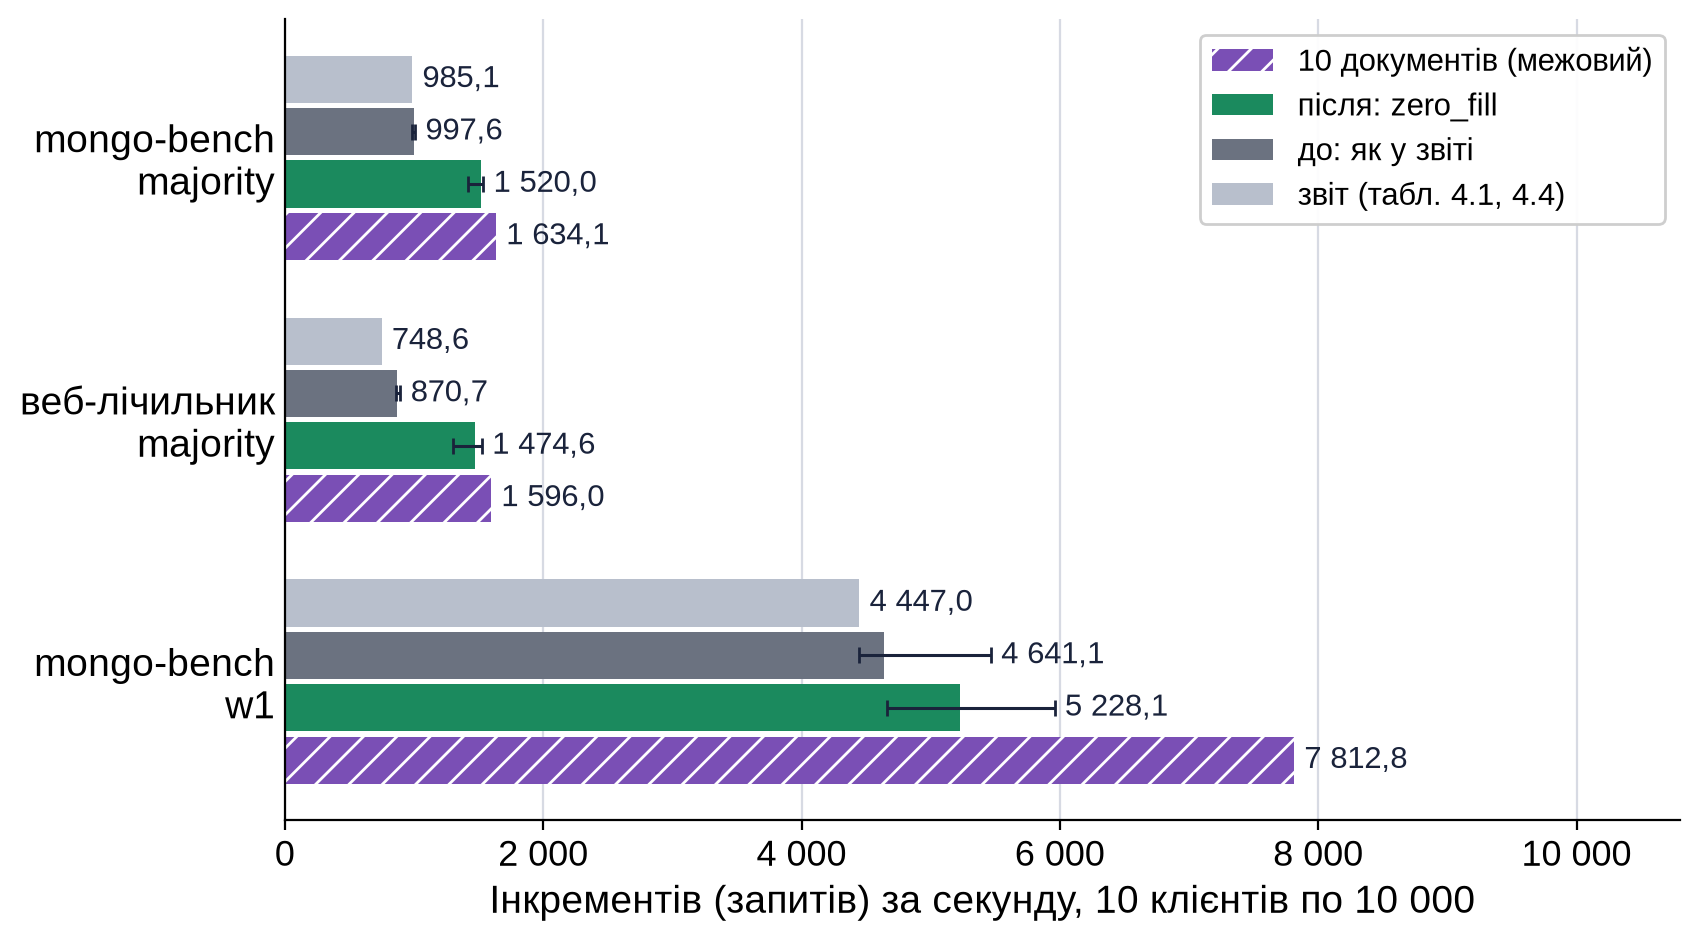

збережено: Labs/04-mongodb/assets/06-extra-throughput.png


In [30]:
BA_COLOR = {"звіт": "#B8BFCC", "до": "#6B7280", "після": "#1B8A5E", "10 документів": "#7A4FB5"}
fig, ax = plt.subplots(figsize=(9, 5.2))
modes = before_after.index.tolist()[::-1]
h = 0.2
for i, mode in enumerate(modes):
    row = before_after.loc[mode]
    for j, key in enumerate(["звіт", "до", "після", "10 документів"]):
        y = i + (1.5 - j) * h
        ax.barh(y, row[key], height=h * 0.9, color=BA_COLOR[key], zorder=2,
                hatch="//" if key == "10 документів" else None, edgecolor="white" if key == "10 документів" else None,
                linewidth=0, label=key if i == 0 else None)
        right = row[key]
        if key in ("до", "після"):
            ax.errorbar(row[key], y, xerr=[[row[key] - row[f"{key} мін."]], [row[f"{key} макс."] - row[key]]],
                        fmt="none", ecolor=INK, elinewidth=1.1, capsize=3, zorder=3)
            right = row[f"{key} макс."]
        ax.text(right + 80, y, uk(row[key], 1), va="center", ha="left", fontsize=11, color=INK)
ax.set_yticks(range(len(modes)), [m.replace(" ", "\n", 1) for m in modes])
ax.set_xlim(0, 10_800)
ax.set_xticks(range(0, 10_001, 2_000), [uk(x) for x in range(0, 10_001, 2_000)])
ax.set_xlabel("Інкрементів (запитів) за секунду, 10 клієнтів по 10 000")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], ["10 документів (межовий)", "після: zero_fill", "до: як у звіті", "звіт (табл. 4.1, 4.4)"],
          loc="upper right", frameon=True, framealpha=0.95, fontsize=11)
save(fig, "06-extra-throughput.png");

## 9. Додаткове дослідження: керована зміна primary і вибори

`scripts/task4x-failover.py` запускає `mongo-bench --step-down-after T` або
`--kill-primary-after T` і з журналів mongod бере час подій від моменту
відмови: DOWN, початок виборів, обрання, дозвіл на запис
(`task4x-failover.csv`). Найдовший окремий інкремент (`longest_op_seconds`)
є лише в рядку CSV `mongo-bench` у протоколах, тому його беремо звідти.

In [31]:
fo = pd.read_csv(DATA / "task4x-failover.csv")
assert len(fo) == 22 and fo["correct"].all() and (fo["final_value"] == EXPECTED).all()
assert (fo["elections"] == 1).all() and (fo["errors"] == 0).all()


def bench_rows(path: Path) -> pd.DataFrame:
    """Рядки CSV mongo-bench з протоколу task4x-failover-*.txt з дослідом, міткою і повтором."""
    rows, key, lines = [], None, path.read_text(encoding="utf-8").splitlines()
    for n, line in enumerate(lines):
        if m := re.match(r"== (\S+) (\S+) run (\d+):", line):
            key = (m[1], m[2], int(m[3]))
        elif line.startswith("variant,") and key:
            rows.append(dict(zip(["experiment", "label", "run"], key))
                        | dict(zip(line.split(","), lines[n + 1].split(","))))
    return pd.DataFrame(rows)


fo_logs = pd.concat([bench_rows(p) for p in sorted(LOGS.glob("task4x-failover-*.txt"))], ignore_index=True)
fo = fo.merge(fo_logs[["experiment", "label", "run", "longest_op_seconds"]], on=["experiment", "label", "run"])
fo["longest_op_seconds"] = fo["longest_op_seconds"].astype(float)
assert len(fo) == 22

sd = fo[(fo.experiment == "stepdown") & fo.label.isin(["w1", "majority"])].sort_values(["label", "run"],
                                                                                       ascending=[False, True])
display(sd[["label", "run", "seconds", "ops_per_s", "final_value", "retries", "election_start_s", "writable_s",
            "failure_to_ack_s", "longest_op_seconds", "stepdown_reply_s"]])
PUBLISHED_511 = [  # (прогін, повтор, час, інкр./с, повтори, вибори, запис, перше підтв., найдовший), таблиця 5.11
    ("w1", 1, 14.27, 7006.5, 20, 0.013, 0.030, 0.043, 0.197),
    ("w1", 2, 15.52, 6441.9, 20, 0.011, 0.024, 0.040, 0.188),
    ("w1", 3, 17.71, 5646.7, 12, 0.012, 0.023, 0.026, 0.135),
    ("majority", 1, 99.06, 1009.5, 17, 0.010, 0.018, 0.023, 0.044),
    ("majority", 2, 98.68, 1013.4, 20, 0.010, 0.018, 0.038, 0.055),
    ("majority", 3, 98.77, 1012.4, 11, 0.009, 0.018, 0.025, 0.053),
]
got = [(r_.label, r_.run, round(r_.seconds, 2), r_.ops_per_s, r_.retries, r_.election_start_s, r_.writable_s,
        r_.failure_to_ack_s, r_.longest_op_seconds) for r_ in sd.itertuples()]
assert got == PUBLISHED_511, got
assert sd.stepdown_reply_s.min() == 0.010 and sd.stepdown_reply_s.max() == 0.014
interrupted = sd.retry_kinds.map(lambda k: sum(int(n) for n in re.findall(r"InterruptedDueToReplStateChange: (\d+)", k)))
assert (interrupted == 10).all(), "кожен з 10 клієнтів отримав одне InterruptedDueToReplStateChange"
other = sd.retries - interrupted
assert other.min() == 1 and other.max() == 10

,label,run,seconds,ops_per_s,final_value,retries,election_start_s,writable_s,failure_to_ack_s,longest_op_seconds,stepdown_reply_s
0,w1,1,14.2725,7006.5,100000,20,0.013,0.030,0.043,0.197,0.014
2,w1,2,15.5235,6441.9,100000,20,0.011,0.024,0.040,0.188,0.012
4,w1,3,17.7094,5646.7,100000,12,0.012,0.023,0.026,0.135,0.013
1,majority,1,99.0607,1009.5,100000,17,0.010,0.018,0.023,0.044,0.011
3,majority,2,98.6812,1013.4,100000,20,0.010,0.018,0.038,0.055,0.011
5,majority,3,98.7722,1012.4,100000,11,0.009,0.018,0.025,0.053,0.010


Таблиця 5.12 звіту: контрольні прогони тієї самої програми, зібраної без
рядка `try? await cluster.reconnect()` (мітка `-noreconnect`).

In [32]:
nr = fo[fo.label.str.endswith("-noreconnect")].sort_values(["label", "run"], ascending=[False, True]).copy()
nr["NotWritablePrimary"] = nr.retry_kinds.str.extract(r"NotWritablePrimary: (\d+)")[0].fillna(0).astype(int)
display(nr[["label", "run", "seconds", "failure_to_ack_s", "longest_op_seconds", "retries", "NotWritablePrimary"]])
PUBLISHED_512 = [  # (прогін, повтор, час, перше підтвердження, найдовший, повтори, NotWritablePrimary)
    ("w1-noreconnect", 1, 18.86, 5.072, 5.199, 240, 230),
    ("w1-noreconnect", 2, 20.59, 5.072, 5.129, 240, 230),
    ("w1-noreconnect", 3, 20.44, 5.075, 5.127, 240, 230),
    ("majority-noreconnect", 1, 104.53, 0.033, 10.088, 146, 132),
    ("majority-noreconnect", 2, 104.42, 0.032, 10.083, 104, 87),
    ("majority-noreconnect", 3, 99.87, 0.032, 0.047, 20, 1),
]
got = [(r_.label, r_.run, round(r_.seconds, 2), r_.failure_to_ack_s, r_.longest_op_seconds, r_.retries,
        r_.NotWritablePrimary) for r_ in nr.itertuples()]
assert got == PUBLISHED_512, got

,label,run,seconds,failure_to_ack_s,longest_op_seconds,retries,NotWritablePrimary
16,w1-noreconnect,1,18.8553,5.072,5.199,240,230
18,w1-noreconnect,2,20.5862,5.072,5.129,240,230
20,w1-noreconnect,3,20.4408,5.075,5.127,240,230
17,majority-noreconnect,1,104.5341,0.033,10.088,146,132
19,majority-noreconnect,2,104.4182,0.032,10.083,104,87
21,majority-noreconnect,3,99.8693,0.032,0.047,20,1


Таблиця 5.13 звіту: SIGKILL primary на 30-й секунді прогону `majority` при
трьох значеннях `electionTimeoutMillis`, по 3 прогони. Випадкова добавка
дорівнює часу до початку виборів мінус `electionTimeoutMillis`.

In [33]:
el = fo[fo.experiment == "election"].copy()
el["добавка, мс"] = (1000 * el.election_start_s - el.election_timeout_ms).round(0)
g = el.groupby("election_timeout_ms")
election = pd.DataFrame({
    "DOWN мін.": g.down_s.min(), "DOWN макс.": g.down_s.max(),
    "вибори мін.": g.election_start_s.min(), "вибори макс.": g.election_start_s.max(),
    "запис мін.": g.writable_s.min(), "запис макс.": g.writable_s.max(),
    "підтв. мін.": g.failure_to_ack_s.min(), "підтв. макс.": g.failure_to_ack_s.max(),
    "підтв. медіана": g.failure_to_ack_s.median(), "прогін медіана": g.seconds.median(),
    "повтори мін.": g.retries.min(), "повтори макс.": g.retries.max(),
    "добавка мін.": g["добавка, мс"].min(), "добавка макс.": g["добавка, мс"].max(),
}).loc[[10000, 2000, 1000]]
display(election)
PUBLISHED_513 = {  # таймаут: (вибори мін., макс., запис мін., макс., підтв. мін., макс., медіана, прогін, повтори)
    10000: (10.053, 10.805, 10.062, 10.820, 10.144, 10.910, 10.144, 106.93, 440, 470),
    2000: (2.015, 2.096, 2.030, 2.107, 2.096, 2.353, 2.112, 98.76, 120, 130),
    1000: (1.006, 1.131, 1.021, 1.146, 1.101, 1.339, 1.105, 98.12, 80, 90),
}
for timeout, values in PUBLISHED_513.items():
    row = election.loc[timeout]
    got = (row["вибори мін."], row["вибори макс."], row["запис мін."], row["запис макс."], row["підтв. мін."],
           row["підтв. макс."], row["підтв. медіана"], round(row["прогін медіана"], 2), row["повтори мін."],
           row["повтори макс."])
    assert got == values, (timeout, got)
assert election["добавка мін."].tolist() == [53, 15, 6] and election["добавка макс."].tolist() == [805, 96, 131]
assert el.down_s.min() == 0.032 and el.down_s.max() == 0.045
client_wait = (el.failure_to_ack_s - el.writable_s).round(3)
print(f"від дозволу на запис до першого підтвердження: {client_wait.min():.3f}...{client_wait.max():.3f} с")
assert client_wait.min() == 0.001 and client_wait.max() == 0.246
switch_ms = (1000 * (el.writable_s - el.election_start_s)).round(0)
print(f"вибори і перехід до запису: {switch_ms.min():.0f}...{switch_ms.max():.0f} мс")
assert (switch_ms.min(), switch_ms.max()) == (9, 19)
loads = pd.concat([tp.loadavg_1m, fo.loadavg_1m, pd.read_csv(DATA / "task4x-failover-pause.csv").loadavg_1m])
print(f"load average за 1 хв на початку прогонів: {loads.min()}...{loads.max()}")
assert (loads.min(), loads.max()) == (2.55, 22.7)

sk = fo[fo.experiment == "stepdown-kill"].iloc[0]
print(f"step-down двічі, потім SIGKILL при 2000 мс: вибори через {sk.election_start_s} с, запис {sk.writable_s} с, "
      f"перше підтвердження {sk.failure_to_ack_s} с, повторів {sk.retries}, прогін {sk.seconds:.2f} с")
assert (sk.election_start_s, sk.writable_s, sk.failure_to_ack_s, sk.retries, round(sk.seconds, 2)) == \
    (49.103, 49.118, 49.356, 2000, 143.84)
smoke = (LOGS / "task4x-failover-smoke-stepdown-period.txt").read_text(encoding="utf-8")
assert re.search(r"^majority,true,10,1000,true,2,[\d.]+,23\.493,", smoke, re.M) and "stepdown period to end" in smoke

,DOWN мін.,DOWN макс.,вибори мін.,вибори макс.,запис мін.,запис макс.,підтв. мін.,підтв. макс.,підтв. медіана,прогін медіана,повтори мін.,повтори макс.,добавка мін.,добавка макс.
election_timeout_ms,,,,,,,,,,,,,,
10000,0.035,0.042,10.053,10.805,10.062,10.820,10.144,10.910,10.144,106.9280,440,470,53.0,805.0
2000,0.033,0.044,2.015,2.096,2.030,2.107,2.096,2.353,2.112,98.7618,120,130,15.0,96.0
1000,0.032,0.045,1.006,1.131,1.021,1.146,1.101,1.339,1.105,98.1204,80,90,6.0,131.0


від дозволу на запис до першого підтвердження: 0.001...0.246 с
вибори і перехід до запису: 9...19 мс
load average за 1 хв на початку прогонів: 2.55...22.7
step-down двічі, потім SIGKILL при 2000 мс: вибори через 49.103 с, запис 49.118 с, перше підтвердження 49.356 с, повторів 2000, прогін 143.84 с


Таблиця 5.14 звіту: заморожений primary (SIGSTOP на 1,5 або 3 с, без
навантаження). З протоколу `task4x-failover-pause.txt` для кожного
заморожування з виборами беремо, коли старий primary склав роль і коли новий
дозволив запис (від SIGSTOP).

In [34]:
pause = pd.read_csv(DATA / "task4x-failover-pause.csv")
frozen = pause[pause.kind == "pause"]
table514 = frozen.assign(with_election=frozen.elections > 0).groupby(["election_timeout_ms", "pause_s"]).agg(
    прогонів=("run", "size"), з_виборами=("with_election", "sum"), виборів=("elections", list)).reset_index()
display(table514)
idle = pause[pause.kind == "idle-60s"]
assert (idle.elections == 0).all() and len(idle) == 3
expected514 = {(10000, 1.5): 0, (10000, 3.0): 0, (2000, 1.5): 0, (2000, 3.0): 3, (1000, 1.5): 3, (1000, 3.0): 3}
for row in table514.itertuples():
    assert row.прогонів == 3 and row.з_виборами == expected514[(row.election_timeout_ms, row.pause_s)]
assert table514.set_index(["election_timeout_ms", "pause_s"]).loc[(1000, 3.0), "виборів"] == [2, 1, 2]

events = []
for block in (LOGS / "task4x-failover-pause.txt").read_text(encoding="utf-8").split("\n== pause ")[1:]:
    head = re.match(r"([\d.]+) s, electionTimeoutMillis (\d+), run (\d+): primary (node\d)", block)
    # Роль складає саме заморожений вузол; при подвійних виборах складає й проміжний primary.
    stepped = re.findall(r"\+([\d.]+) s\s+" + head[4]
                         + r"\s+Replica set state transition\s+\{\"newState\":\"SECONDARY\",\"oldState\":\"PRIMARY\"", block)
    writable = re.findall(r"\+([\d.]+) s\s+node\d\s+Transition to primary complete", block)
    if writable:
        events.append({"pause_s": float(head[1]), "timeout": int(head[2]), "run": int(head[3]),
                       "старий склав роль": float(stepped[0]), "запис дозволено": float(writable[-1])})
events = pd.DataFrame(events)
events["запис після складання, с"] = (events["запис дозволено"] - events["старий склав роль"]).round(3)
display(events)
assert len(events) == 9
assert events["запис після складання, с"].min() == 0.002 and events["запис після складання, с"].max() == 0.015
w15, w30 = events[events.pause_s == 1.5]["запис дозволено"], events[events.pause_s == 3.0]["запис дозволено"]
assert (w15.min(), w15.max(), w30.min(), w30.max()) == (1.539, 1.545, 3.031, 3.047)
probe_log = (LOGS / "task4x-failover-pause-probe.txt").read_text(encoding="utf-8")
assert "Can't see a majority of the set, relinquishing primary" in probe_log and "catch-up" in probe_log
# Друга перевірка: 2000 мс, заморожування на 13 с. Події беремо після її SIGSTOP.
stop2 = pd.Timestamp("2026-11-10T" + re.search(r"electionTimeoutMillis 2000, SIGSTOP node\d о (\S+),", probe_log)[1])
probe_events = [(pd.Timestamp("2026-11-10T" + m[1]), m[2], m[3]) for m in
                re.finditer(r"^(\d\d:\d\d:\d\d\.\d{3}) (node\d) (.*)$", probe_log, re.M)]
second = [(t, node, msg) for t, node, msg in probe_events if t > stop2]
terms2 = [int(re.search(r'"term":(\d+)', msg)[1]) for _, _, msg in second if msg.startswith("Election succeeded")]
writable2 = next(t for t, _, msg in second if msg.startswith("Transition to primary complete"))
rb_in = next(t for t, _, msg in second if '"newState":"ROLLBACK"' in msg and msg.startswith("Replica set state transition"))
rb_out = next(t for t, _, msg in second if '"oldState":"ROLLBACK"' in msg)
print(f"2000 мс, пауза 13 с: вибори в термах {terms2}, запис через {(writable2 - stop2).total_seconds():.2f} с "
      f"після SIGSTOP, ROLLBACK старого primary {(rb_out - rb_in).total_seconds():.2f} с")
assert terms2 == [4, 5, 6] and round((writable2 - stop2).total_seconds(), 2) == 11.08
assert round((rb_out - rb_in).total_seconds(), 2) == 0.29

,election_timeout_ms,pause_s,прогонів,з_виборами,виборів
0,1000,1.5,3,3,"[1, 1, 1]"
1,1000,3.0,3,3,"[2, 1, 2]"
2,2000,1.5,3,0,"[0, 0, 0]"
3,2000,3.0,3,3,"[1, 1, 1]"
4,10000,1.5,3,0,"[0, 0, 0]"
5,10000,3.0,3,0,"[0, 0, 0]"


,pause_s,timeout,run,старий склав роль,запис дозволено,"запис після складання, с"
0,3.0,2000,1,3.029,3.041,0.012
1,1.5,1000,1,1.530,1.540,0.010
2,3.0,1000,1,3.035,3.047,0.012
3,3.0,2000,2,3.029,3.031,0.002
4,1.5,1000,2,1.529,1.539,0.010
5,3.0,1000,2,3.028,3.039,0.011
6,3.0,2000,3,3.029,3.039,0.010
7,1.5,1000,3,1.530,1.545,0.015
8,3.0,1000,3,3.031,3.043,0.012


2000 мс, пауза 13 с: вибори в термах [4, 5, 6], запис через 11.08 с після SIGSTOP, ROLLBACK старого primary 0.29 с


Рисунок 5.12 звіту: з чого складається пауза в записі. Для кожного прогону
з таблиць 5.11 і 5.13: очікування до початку виборів, вибори і перехід до
запису, очікування клієнта до першого підтвердження.

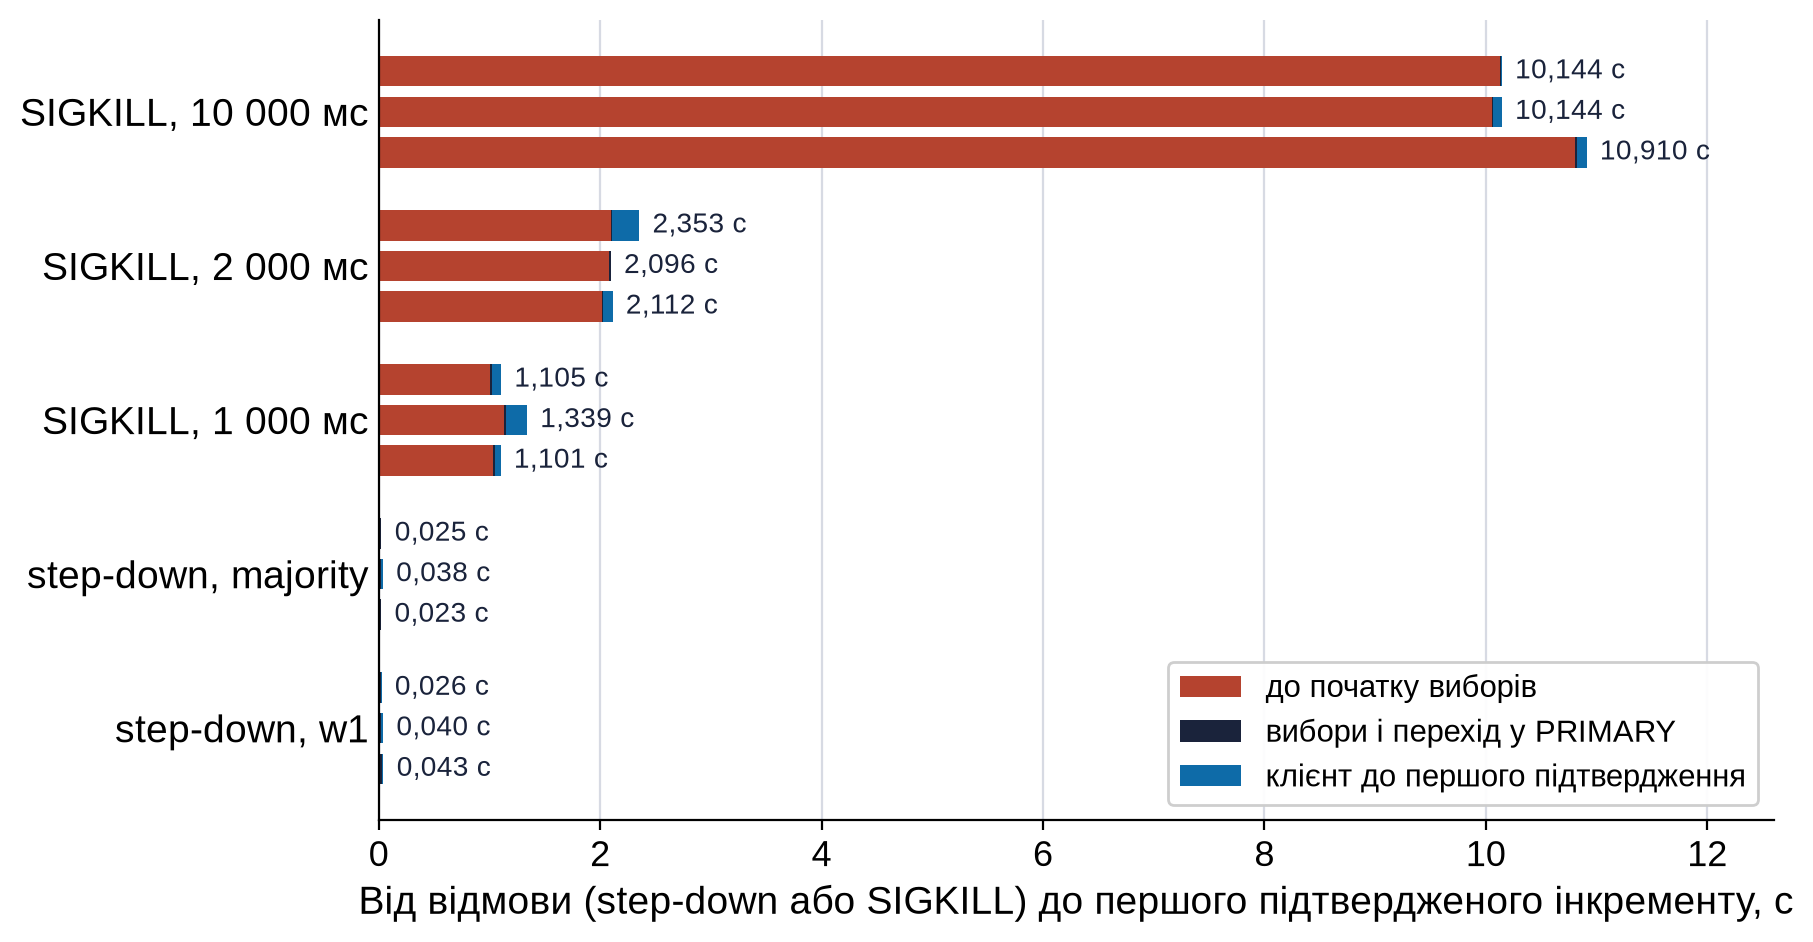

збережено: Labs/04-mongodb/assets/07-extra-election.png


In [35]:
parts = pd.concat([
    sd.assign(group="step-down, " + sd.label),
    el.assign(group="SIGKILL, " + el.election_timeout_ms.map(lambda t: uk(t)) + " мс"),
])
parts["до виборів"] = parts.election_start_s
parts["вибори і перехід"] = parts.writable_s - parts.election_start_s
parts["клієнт"] = parts.failure_to_ack_s - parts.writable_s
order_groups = ["SIGKILL, 10\u00a0000 мс", "SIGKILL, 2\u00a0000 мс", "SIGKILL, 1\u00a0000 мс",
                "step-down, majority", "step-down, w1"]
SEG_COLOR = {"до виборів": "#B5432F", "вибори і перехід": "#1A233B", "клієнт": "#0E6BA8"}
fig, ax = plt.subplots(figsize=(9, 5.2))
y, ticks = 0, []
for grp in order_groups[::-1]:
    rows = parts[parts.group == grp].sort_values("run")
    ticks.append((y + (len(rows) - 1) / 2, grp))
    for r_ in rows.itertuples():
        left = 0.0
        for seg in SEG_COLOR:
            v = rows.loc[r_.Index, seg]
            ax.barh(y, v, left=left, height=0.75, color=SEG_COLOR[seg], zorder=2,
                    label=seg if y == 0 else None)
            left += v
        ax.text(left + 0.12, y, uk(r_.failure_to_ack_s, 3) + " с", va="center", ha="left", fontsize=10, color=INK)
        y += 1
    y += 0.8
ax.set_yticks([t for t, _ in ticks], [g_ for _, g_ in ticks])
ax.set_xlim(0, 12.6)
ax.set_xlabel("Від відмови (step-down або SIGKILL) до першого підтвердженого інкременту, с")
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.legend(["до початку виборів", "вибори і перехід у PRIMARY", "клієнт до першого підтвердження"],
          loc="lower right", frameon=True, framealpha=0.95, fontsize=11)
save(fig, "07-extra-election.png");

## 10. Жива перевірка

Цей розділ запускає справжній replica set і бінарник `mongo-bench` зі
`Sources/` на зменшеному навантаженні: 10 клієнтів по 300 інкрементів
(3 000 замість 100 000) з `w: 1` і з `w: "majority"`, без відмов. Він лише
перевіряє, що код працює і лічильник точний; числа звіту взято з CSV у
розділах 4, 6 і 7...9.

Дані й логи вузлів ідуть у тимчасову теку (`MONGO_DATA_DIR`,
`HLS_LOG_DIR`), тож ні `.mongodata`, ні `reports/logs` не змінюються.
Кластер зупиняється в `finally`. Якщо replica set на портах 21430...21432
уже працює, клітинка використовує його і не зупиняє.

In [36]:
def sh(cmd: str, timeout: int, env: dict | None = None, check: bool = True) -> subprocess.CompletedProcess:
    """Виконати команду bash у корені репозиторію з оточенням scripts/env.sh."""
    full_env = {**os.environ, **(env or {})}
    proc = subprocess.run(["bash", "-lc", f"cd '{ROOT}' && source scripts/env.sh && {cmd}"],
                          capture_output=True, text=True, timeout=timeout, env=full_env)
    if check and proc.returncode != 0:
        raise RuntimeError(f"`{cmd}` завершилася з кодом {proc.returncode}:\n"
                           + proc.stdout[-2000:] + proc.stderr[-2000:])
    return proc


def port_open(port: int) -> bool:
    with socket.socket() as s:
        s.settimeout(0.3)
        return s.connect_ex(("127.0.0.1", port)) == 0

In [37]:
live = None
if RUN_LIVE:
    work = Path(tempfile.mkdtemp(prefix="hls-nb04-"))
    env = {"HLS_LOG_DIR": str(work / "logs"), "MONGO_DATA_DIR": str(work / "data")}
    started = False
    rows, live_logs, status = [], {}, ""
    t0 = time.monotonic()
    try:
        sh("test -x .build/release/mongo-bench || hls_build_release --product mongo-bench", timeout=900, env=env)
        if not any(port_open(21430 + i) for i in range(3)):
            started = True
            sh("scripts/mongo.sh start", timeout=180, env=env)
        sh("scripts/mongo.sh wait-primary", timeout=60, env=env)
        print(f"replica set готовий за {time.monotonic() - t0:.1f} с")
        for variant in ("w1", "majority"):
            res = sh(f'"$HLS_BIN/mongo-bench" --header --variant {variant} --workers 10 --increments 300 '
                     '--url "$MONGO_URL" --mongo-script scripts/mongo.sh', timeout=120, env=env)
            rows.append(pd.read_csv(pd.io.common.StringIO(res.stdout)))
        status = sh("scripts/mongo.sh status", timeout=30, env=env).stdout
        for node in (1, 2, 3):
            path = work / "logs" / f"mongo-node{node}.log"
            if path.exists():
                live_logs[node] = path.read_text(encoding="utf-8", errors="replace").splitlines()
    finally:
        if started:
            sh("scripts/mongo.sh stop", timeout=180, env=env, check=False)
        shutil.rmtree(work, ignore_errors=True)
    print(f"разом {time.monotonic() - t0:.1f} с, replica set {'зупинено' if started else 'лишився працювати'}")
    print(status)

    live = pd.concat(rows, ignore_index=True)
    display(live[["variant", "workers", "increments_per_worker", "seconds", "ops_per_sec",
                  "final_value", "expected", "acknowledged", "lost", "retries", "errors"]])
    for node, lines in live_logs.items():
        hit = next((json.loads(l) for l in lines if "Election succeeded" in l), None)
        print(f"mongo-node{node}.log: {len(lines)} рядків"
              + (f"; {hit['t']['$date']} {hit['msg']} {hit['attr']}" if hit else ""))
else:
    print("RUN_LIVE = False: replica set не запускався")

replica set готовий за 14.3 с


разом 31.7 с, replica set зупинено
rs0, term 1, seen from node1
node1  127.0.0.1:21430  PRIMARY                   health 1  optime 1794325601:14486  (pid 403937)
node2  127.0.0.1:21431  SECONDARY                 health 1  optime 1794325601:9686  lag 0 s  sync node1  (pid 404034)
node3  127.0.0.1:21432  SECONDARY                 health 1  optime 1794325601:9686  lag 0 s  sync node1  (pid 404131)



,variant,workers,increments_per_worker,seconds,ops_per_sec,final_value,expected,acknowledged,lost,retries,errors
0,w1,10,300,0.3804,7885.7,3000,3000,3000,0,0,0
1,majority,10,300,0.5676,5285.2,3000,3000,3000,0,0,0


mongo-node1.log: 690 рядків; 2026-11-10T15:46:39.289Z Election succeeded, assuming primary role {'term': 1}
mongo-node2.log: 617 рядків
mongo-node3.log: 610 рядків


In [38]:
if live is not None:
    ints = live.set_index("variant")[["final_value", "expected", "acknowledged", "lost"]].astype(int)
    for variant, row in ints.iterrows():
        print(f"{variant}: {row.final_value} з {row.expected}, підтверджено {row.acknowledged}, втрачено {row.lost}")
    assert (ints["final_value"] == ints["expected"]).all()
    assert (ints["acknowledged"] == ints["expected"]).all()

w1: 3000 з 3000, підтверджено 3000, втрачено 0
majority: 3000 з 3000, підтверджено 3000, втрачено 0


Без відмов обидва write concern дають рівно 3 000. Час тут не показовий:
прогін короткий, а вузли щойно стартували.

## 11. Висновки

1. Replica set з трьох вузлів (P-S-S): `w: 3` без тайм-ауту чекає, доки повернеться вимкнений вузол (10,623 с),
   а з `wtimeout: 5000` повертає `WriteConcernTimeout`, проте документ
   лишається записаним і читається з `readConcern("majority")`. Після
   зупинки primary новий обирається за 0,029 с при штатній зупинці і за
   10,3...11,3 с після SIGKILL; старий primary повертається як SECONDARY з
   усіма даними, записаними без нього.
2. Без відмов обидва write concern точні (100 000), але `majority` у 4,5
   раза повільніший (101,52 проти 22,49 с), бо кожен інкремент чекає
   журналу на більшості вузлів.
3. З `w: 1` раптова відмова primary втратила 4, 1 і 0 підтверджених
   інкрементів, без rollback: їх не було ні на secondary, ні в журналі
   старого primary.
4. З `w: "majority"` і retryable writes фінальне значення рівно 100 000 у
   всіх трьох прогонах з відмовою; сервер упізнав 7...10 повторів як уже
   виконані. Без `lsid` і `txnNumber` той самий сценарій дав 100 010.
5. Як сховище веб-лічильника MongoDB з `majority` дав 748,6 запитів/с:
   швидше за PostgreSQL (330,6) і файл з `fsync` (122,2), повільніше за
   Hazelcast (11 259,7) і пам'ять (31 256,0).
6. Підтверджені з `{ w: 1, j: true }` записи, яких не мав жоден secondary,
   після повернення старого primary відкочено в rollback-файли: 5 вставок і
   5 інкрементів, 6 документів і 12 записів oplog, однаково після SIGSTOP і
   SIGKILL.
7. `local` двічі показав дані, які потім відкотили; `majority` ні, але на
   відсталому secondary і він повертає застаріле значення. Свіже значення
   гарантує лише `linearizable` на primary.
8. Відмову primary видно в максимумі затримки (10,4 с) і як 10,40 с без
   підтверджень, а p99,9 з відмовою і без неї однаковий.
9. Обмеження `majority` у синхронізації журналу; `log=(zero_fill=true)`
   прибирає unwritten extents і дає 1 520,0 інкр./с замість 997,6 у
   `mongo-bench` і 1 474,6 замість 870,7 у веб-лічильнику без зміни правил.
10. `replSetStepDown` зупиняє запис на 0,023...0,043 с; `electionTimeoutMillis`
    2 000 і 1 000 мс скорочують простій після SIGKILL до 2,1 і 1,1 с, але
    дають вибори вже від кількасекундного зависання primary.